# РОЗДІЛ 2. РОЗВ’ЯЗАННЯ ТА АНАЛІЗ ПРЯМОЇ ЗАДАЧІ КОЛИВАНЬ СТРУНИ

Магістерська робота: **«Ідентифікація параметрів коливань закріпленої струни на основі методу головних компонентів (PCA) та регресійних моделей машинного навчання»**

У цьому ноутбуці реалізовано повний цикл аналітичного та чисельного моделювання **прямої задачі** вільних поперечних коливань однорідної пружної струни, жорстко закріпленої на кінцях $x=0$ та $x=l$:
- **Підрозділ 2.1.** Математична постановка початково-крайової задачі та базові фізичні параметри системи.
- **Підрозділ 2.2.** Побудова аналітичного розв’язку методом відокремлення змінних (Фур’є) (**Рисунок 2.1**).
- **Підрозділ 2.3.** Дослідження збіжності тригонометричного ряду за критерієм Коші ($N \to 2N$) та вибір кількості гармонік $K=41$ для досягнення відносної похибки $\varepsilon = 10^{-6}$ (**Таблиці 2.1, 2.2**, **Рисунок 2.2**).
- **Підрозділ 2.4.** Параметричний аналіз хвильового поля $U(x,t)$ при варіації фазової швидкості $a$, довжини струни $l$ та кривини початкового прогину $A$ (**Таблиці 2.3–2.8**, **Рисунки 2.3–2.9**).

## 2.1. Постановка задачі та базові фізичні параметри моделі

Рівняння вільних поперечних коливань однорідної струни має вигляд:
$$\frac{\partial^2 U}{\partial t^2} = a^2 \frac{\partial^2 U}{\partial x^2}, \quad 0 < x < l, \quad t > 0$$

із однорідними граничними умовами Діріхле (жорстке закріплення кінців):
$$U(0, t) = 0, \quad U(l, t) = 0, \quad t \ge 0$$

та початковими умовами параболічного відтягнення без початкової швидкості:
$$U(x, 0) = \varphi(x) = A x (l - x), \quad \left.\frac{\partial U}{\partial t}\right|_{t=0} = 0, \quad x \in [0, l].$$

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

mpl.rcParams["font.family"] = "DejaVu Serif"
mpl.rcParams["mathtext.fontset"] = "stix"
mpl.rcParams["axes.unicode_minus"] = True

# Базові параметри фізичної системи (у системі СІ)
l = 1.0          # Довжина струни між опорами, м
a = 1.0          # Фазова швидкість поширення хвилі, м/с
A = 1.0          # Параметр кривини початкового параболічного прогину, м^-1
h_max = A * (l ** 2) / 4.0  # Максимальний початковий прогин у центрі h = Al^2/4, м
T_period = 2.0 * l / a      # Основний період власних коливань T = 2l/a, с
eps_target = 1e-6           # Цільовий поріг відносної похибки ряду Фур'є
Nx, Nt = 200, 400

def U_func(x, t, K=41, a_val=1.0, l_val=1.0, A_val=1.0):
    """Часткова сума ряду Фур'є з K непарних гармонік (формула (2.27))."""
    k = np.arange(0, K, dtype=np.float64)
    m = 2.0 * k + 1.0
    coeff = 8.0 * A_val * (l_val ** 2) / (np.pi ** 3)
    terms = (coeff / (m ** 3)) * np.cos(m * np.pi * a_val * t / l_val) * np.sin(m * np.pi * x / l_val)
    return float(np.sum(terms))

def U_func_grid(X, T, K=41, a_val=1.0, l_val=1.0, A_val=1.0):
    """Векторизоване обчислення хвильового поля U(x, t) на сітці (X, T)."""
    res = np.zeros_like(X, dtype=np.float64)
    coeff = 8.0 * A_val * (l_val ** 2) / (np.pi ** 3)
    for k in range(K):
        m = 2.0 * k + 1.0
        res += (coeff / (m ** 3)) * np.cos(m * np.pi * a_val * T / l_val) * np.sin(m * np.pi * X / l_val)
    return res

def U_dalembert_exact(x, t, a_val=1.0, l_val=1.0, A_val=1.0):
    """Точний аналітичний розв'язок у формі Даламбера (формула (2.26))."""
    def phi_ext(xi):
        period = 2.0 * l_val
        r = xi % period
        if r <= l_val:
            return A_val * r * (l_val - r)
        r2 = period - r
        return -A_val * r2 * (l_val - r2)
    return 0.5 * (phi_ext(x - a_val * t) + phi_ext(x + a_val * t))

def fmt_sci_ua(val, decimals=4):
    if val == 0:
        return "0,00"
    exp = int(np.floor(np.log10(abs(val))))
    mant = val / (10.0 ** exp)
    return f"{mant:.{decimals}f}".replace(".", ",") + f"·10^{exp}"

print("=" * 85)
print("Підрозділ 2.1. Базові фізичні параметри системи (СІ):")
print(f"  1. Довжина струни між опорами       : l = {l:.2f} м")
print(f"  2. Фазова швидкість хвилі           : a = {a:.2f} м/с")
print(f"  3. Параметр кривини параболи        : A = {A:.2f} м^-1")
print(f"  4. Стріла початкового прогину       : h = phi(l/2) = A*l^2/4 = {h_max:.4f} м")
print(f"  5. Основний період коливань         : T = 2l/a = {T_period:.3f} с (f1 = {1.0/T_period:.3f} Гц)")
print(f"  6. Задана границя відносної похибки : eps = {eps_target:.1e}")
print("=" * 85)

Підрозділ 2.1. Базові фізичні параметри системи (СІ):
  1. Довжина струни між опорами       : l = 1.00 м
  2. Фазова швидкість хвилі           : a = 1.00 м/с
  3. Параметр кривини параболи        : A = 1.00 м^-1
  4. Стріла початкового прогину       : h = phi(l/2) = A*l^2/4 = 0.2500 м
  5. Основний період коливань         : T = 2l/a = 2.000 с (f1 = 0.500 Гц)
  6. Задана границя відносної похибки : eps = 1.0e-06


## 2.2. Побудова аналітичного розв’язку методом відокремлення змінних (Фур’є) (**Рисунок 2.1**)

Аналітичний розв’язок задачі подається у вигляді тригонометричного ряду за непарними гармоніками $n = 2k+1$ (формула (2.24)):
$$U(x, t) = \frac{8 A l^2}{\pi^3} \sum_{k=0}^{\infty} \frac{1}{(2k+1)^3} \cos\!\left(\frac{(2k+1)\pi a t}{l}\right) \sin\!\left(\frac{(2k+1)\pi x}{l}\right).$$

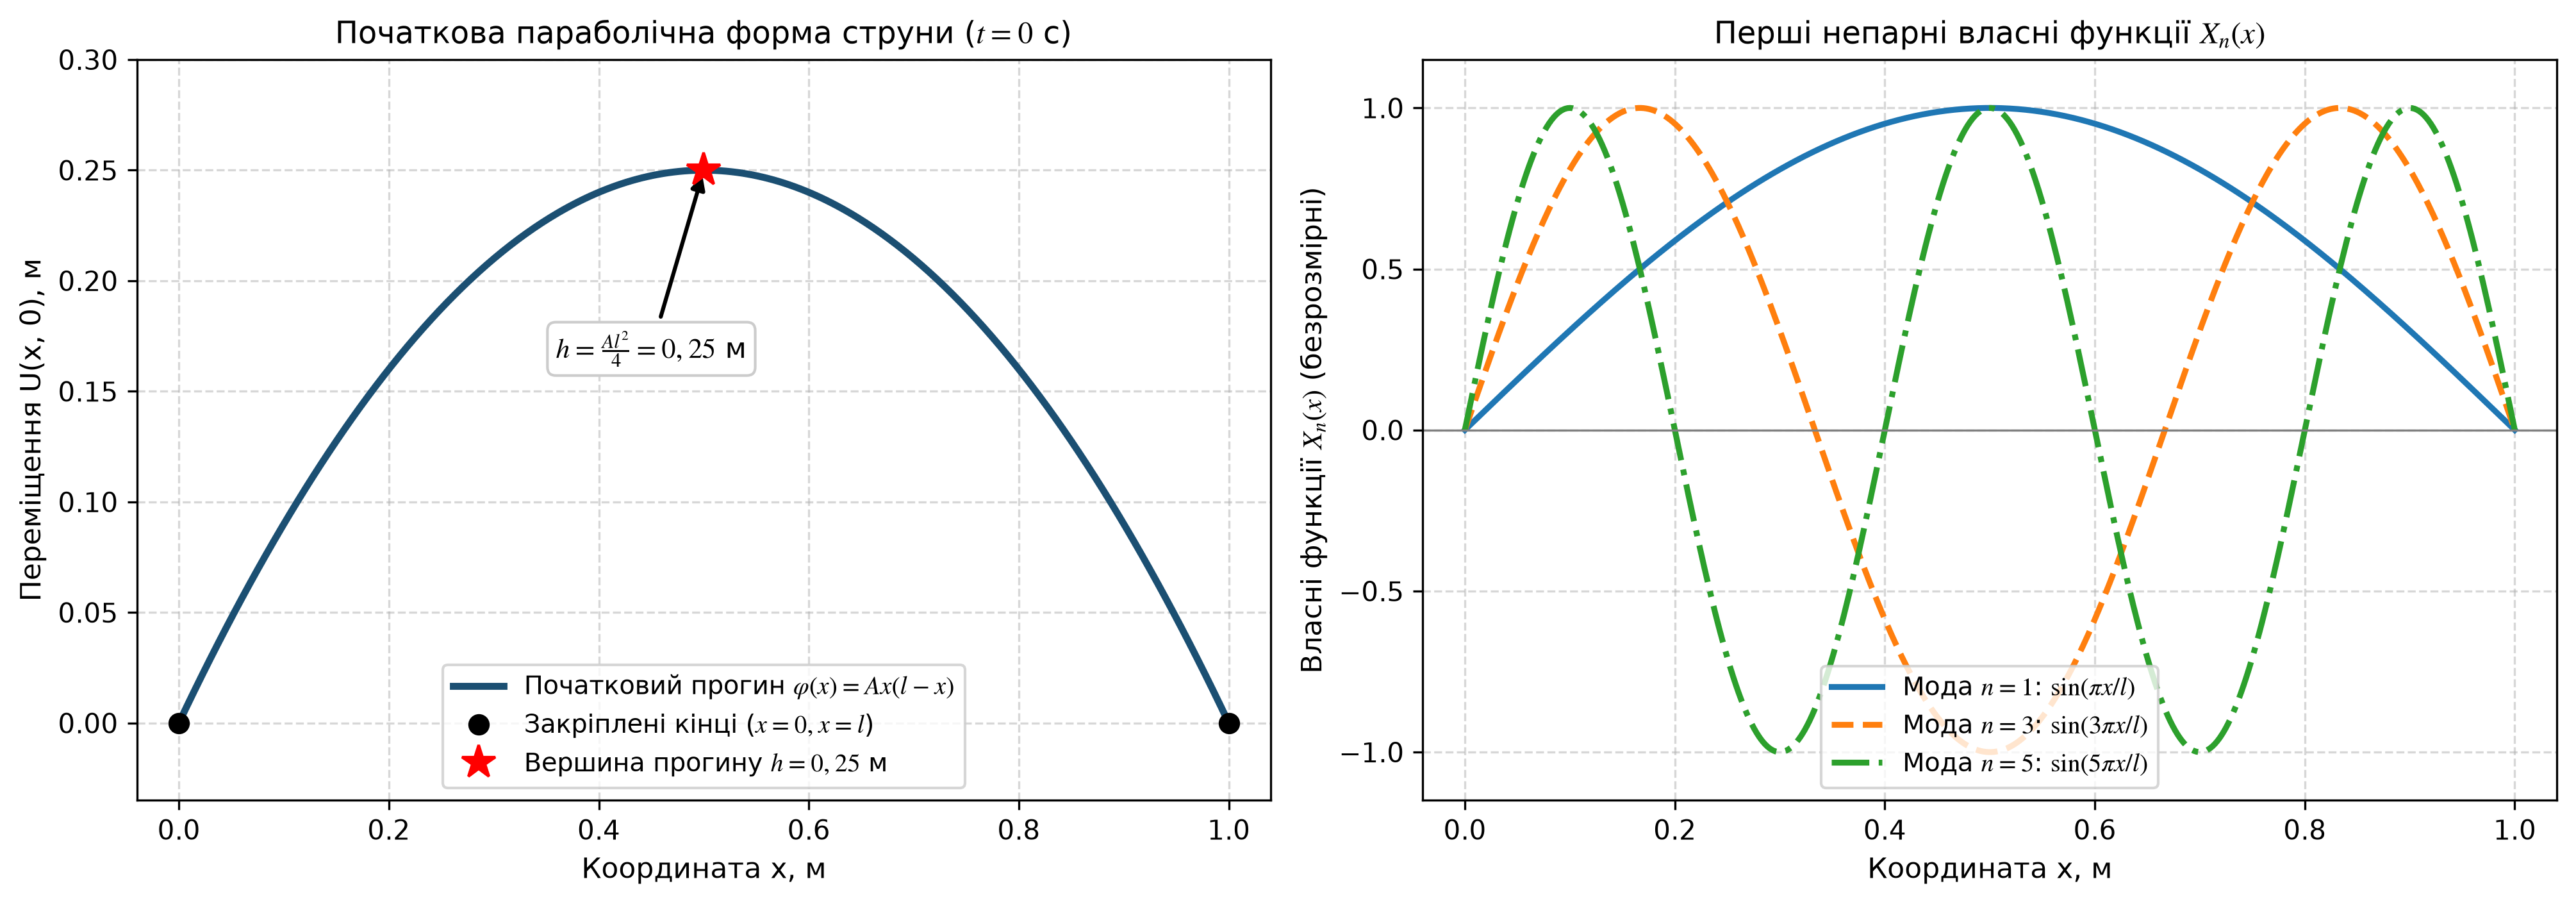

In [2]:
# Рисунок 2.1: Профіль початкового параболічного прогину струни phi(x) = Ax(l-x) (а)
# та просторові форми перших непарних власних мод коливань X_n(x) = sin(n*pi*x/l) при n=1,3,5 (б)
x_plot = np.linspace(0.0, l, 400)
phi_plot = A * x_plot * (l - x_plot)

fig2_1, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=150)

ax1.plot(x_plot, phi_plot, color="#1b4f72", lw=2.6, label=r"Початковий прогин $\varphi(x) = Ax(l - x)$")
ax1.plot([0.0, l], [0.0, 0.0], "ko", ms=7, label=r"Закріплені кінці ($x = 0, x = l$)")
ax1.plot(0.5 * l, h_max, "r*", ms=13, zorder=5, label=r"Вершина прогину $h = 0,25$ м")
ax1.annotate(
    r"$h = \frac{Al^2}{4} = 0,25$ м",
    xy=(0.5 * l, h_max), xytext=(0.45 * l, 0.165), ha="center", fontsize=10.5,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#cccccc"),
    arrowprops=dict(arrowstyle="-|>", lw=1.5, color="black"),
)
ax1.set_title("Початкова параболічна форма струни ($t = 0$ с)", fontsize=11.5)
ax1.set_xlabel("Координата x, м", fontsize=10.5)
ax1.set_ylabel("Переміщення U(x, 0), м", fontsize=10.5)
ax1.set_xlim(-0.04, 1.04)
ax1.set_ylim(-0.035, 0.30)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="lower center", fontsize=9.5, frameon=True)

modes_cfg = [
    (1, "-", "#1f77b4", r"Мода $n = 1$: $\sin(\pi x/l)$"),
    (3, "--", "#ff7f0e", r"Мода $n = 3$: $\sin(3\pi x/l)$"),
    (5, "-.", "#2ca02c", r"Мода $n = 5$: $\sin(5\pi x/l)$"),
]
for n_mode, ls, col, lbl in modes_cfg:
    ax2.plot(x_plot, np.sin(n_mode * np.pi * x_plot / l), linestyle=ls, color=col, lw=2.2, label=lbl)
ax2.axhline(0, color="gray", lw=0.8)
ax2.set_title(r"Перші непарні власні функції $X_n(x)$", fontsize=11.5)
ax2.set_xlabel("Координата x, м", fontsize=10.5)
ax2.set_ylabel(r"Власні функції $X_n(x)$ (безрозмірні)", fontsize=10.5)
ax2.set_xlim(-0.04, 1.04)
ax2.set_ylim(-1.15, 1.15)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="lower center", fontsize=9.5, frameon=True)

plt.tight_layout()
plt.show()

## 2.3. Дослідження збіжності ряду та оцінки похибки (**Таблиці 2.1, 2.2**, **Рисунок 2.2**)

Перевіряємо критерій Коші при подвоєнні кількості членів ряду $N \to 2N$ (**Таблиця 2.1**) та протокол досягнення відносної похибки $\delta_K \le 10^{-6}$ при $K = 41$ (**Таблиця 2.2**, **Рисунок 2.2**).

 ТАБЛИЦЯ 2.1 – Перевірка критерію Коші (N -> 2N) та порядку збіжності p у точці x = l/2, t = 0 
Кількість членів N | Подвоєна 2N  |  U_N(l/2,0), м  | U_2N(l/2,0), м  | Різниця Коші ΔU(N), м | Порядок p 
----------------------------------------------------------------------------------------------------
        16         |      32      |   0,24999609    |   0,24999951    |     3,4228·10^-6      |     –     
        32         |      64      |   0,24999951    |   0,24999994    |     4,2991·10^-7      |   2,9931  
        64         |     128      |   0,24999994    |   0,24999999    |     5,3804·10^-8      |   2,9983  
       128         |     256      |   0,24999999    |   0,25000000    |     6,7275·10^-9      |   2,9996  
       256         |     512      |   0,25000000    |   0,25000000    |     8,4100·10^-10     |   2,9999  
       512         |     1024     |   0,25000000    |   0,25000000    |     1,0513·10^-10     |   3,0000  
       1024        |     2048     |   0,25000000    | 

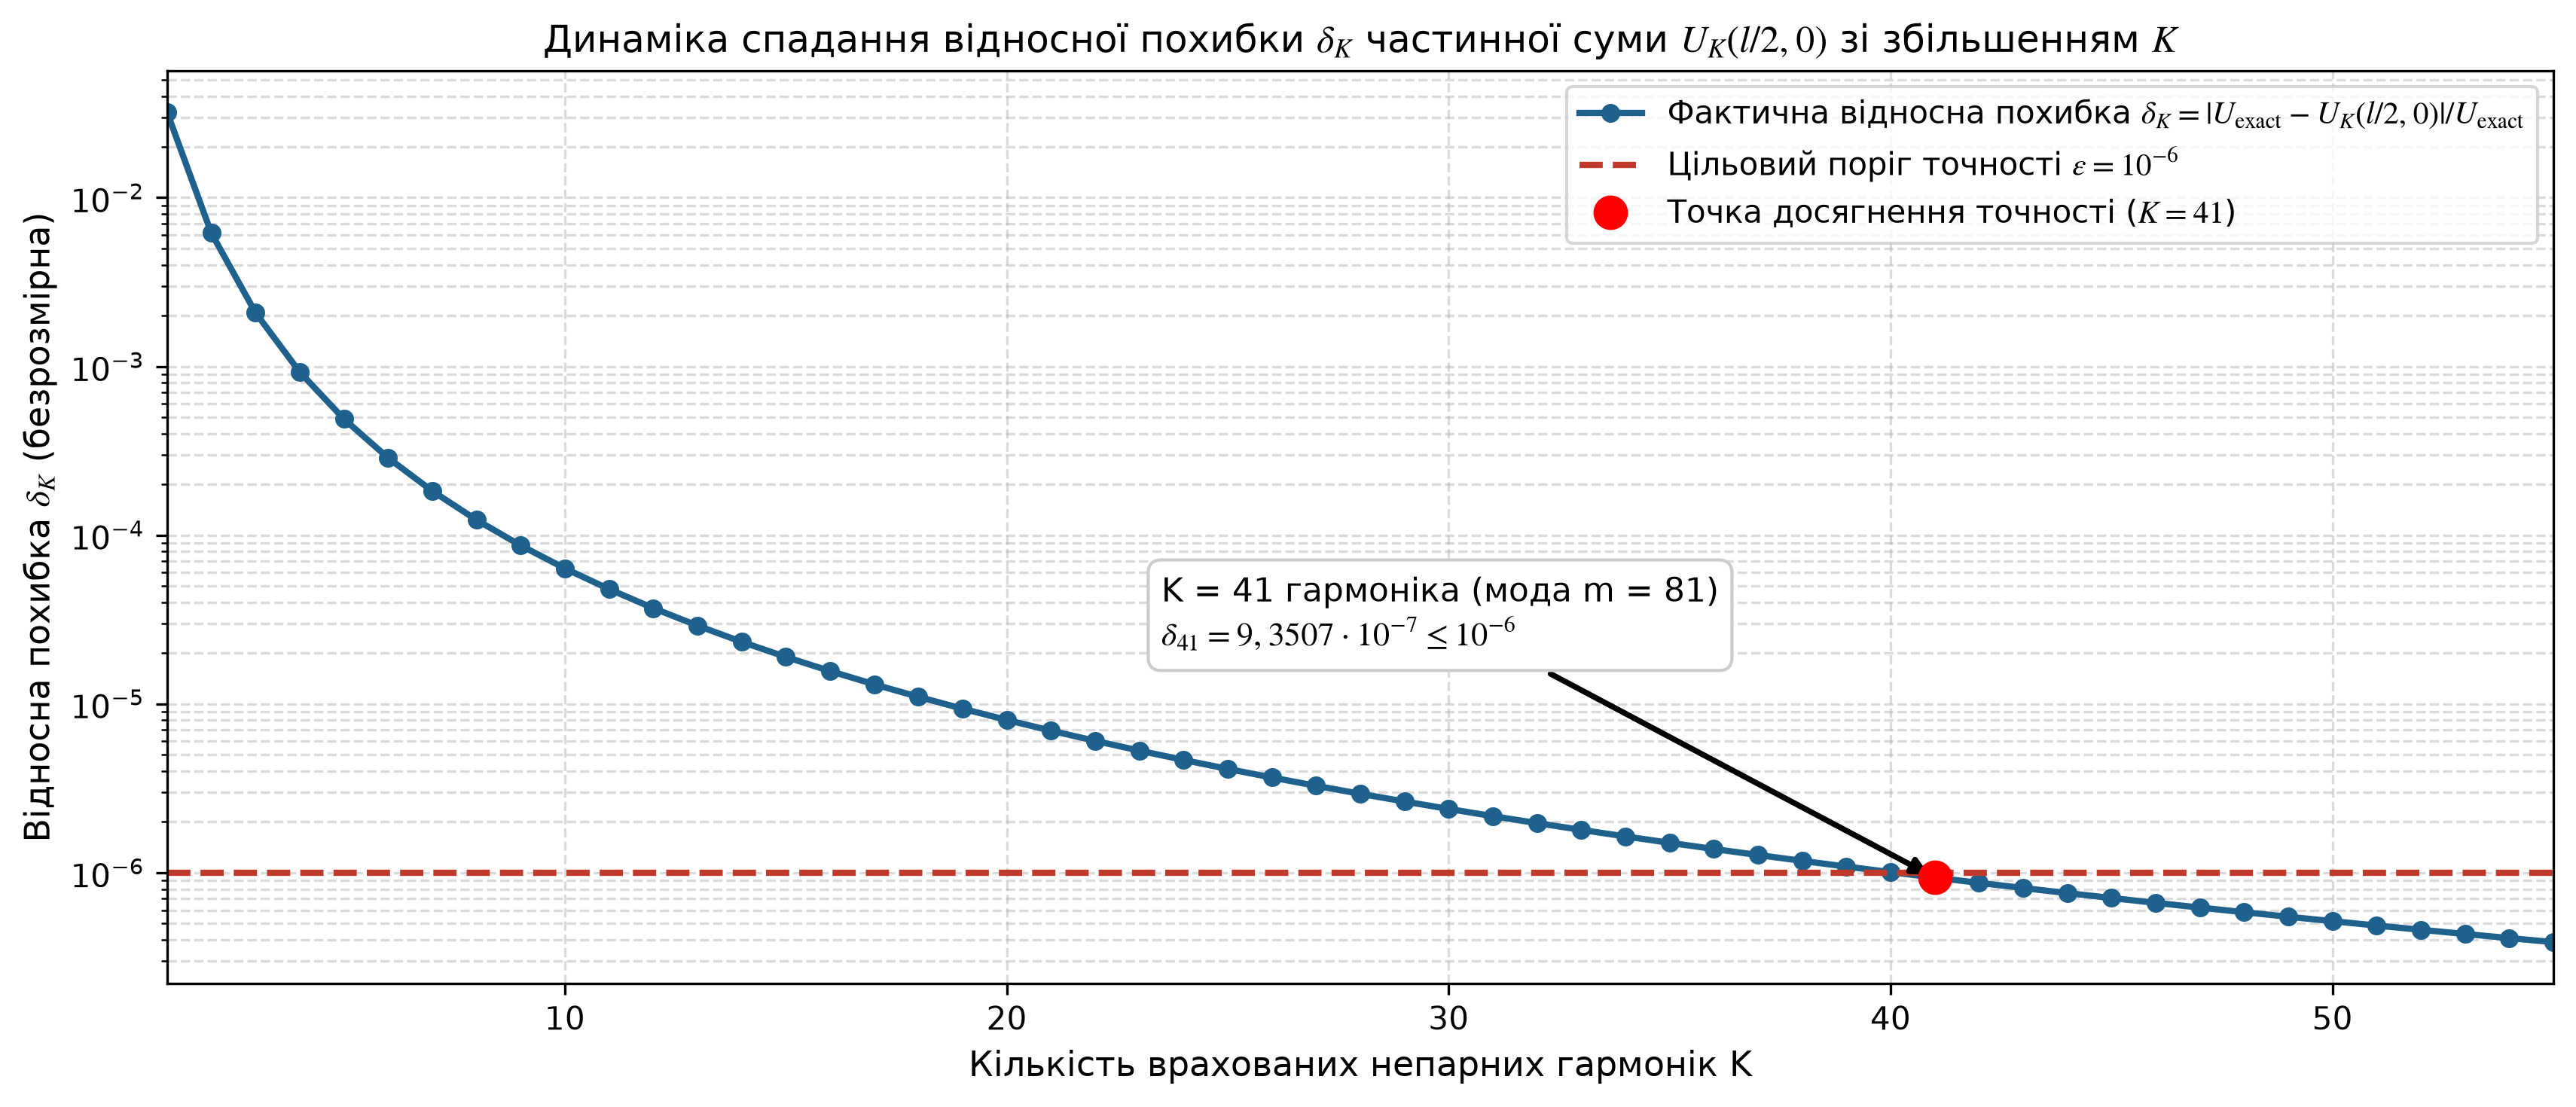

In [3]:
# Таблиця 2.1: Перевірка критерію Коші (N -> 2N) та порядку збіжності p
print("=" * 100)
print(" ТАБЛИЦЯ 2.1 – Перевірка критерію Коші (N -> 2N) та порядку збіжності p у точці x = l/2, t = 0 ")
print("=" * 100)
print(f"{'Кількість членів N':^18} | {'Подвоєна 2N':^12} | {'U_N(l/2,0), м':^15} | {'U_2N(l/2,0), м':^15} | {'Різниця Коші ΔU(N), м':^21} | {'Порядок p':^10}")
print("-" * 100)

N_list = [16, 32, 64, 128, 256, 512, 1024, 2048, 4096, 8192, 16384]
prev_diff = None
for N_val in N_list:
    N2_val = 2 * N_val
    u_N = U_func(0.5 * l, 0.0, N_val, a, l, A)
    u_2N = U_func(0.5 * l, 0.0, N2_val, a, l, A)
    diff = abs(u_2N - u_N)
    p_str = "–" if prev_diff is None else f"{np.log2(prev_diff / diff):.4f}".replace(".", ",")
    prev_diff = diff
    print(f"{N_val:^18d} | {N2_val:^12d} | {f'{u_N:.8f}'.replace('.', ','):^15} | {f'{u_2N:.8f}'.replace('.', ','):^15} | {fmt_sci_ua(diff, 4):^21} | {p_str:^10}")
print("=" * 100)

# Таблиця 2.2: Протокол прямого обчислення абсолютної R_K та відносної delta_K похибок
print("\n" + "=" * 105)
print(" ТАБЛИЦЯ 2.2 – Протокол прямого обчислення абсолютної R_K та відносної δ_K похибок ряду Фур’є до ε = 10^-6 ")
print("=" * 105)
print(f"{'Кількість членів K':^18} | {'Мода m=2K-1':^12} | {'Часткова сума U_K, м':^20} | {'Абс. похибка R_K, м':^19} | {'Відн. похибка δ_K':^19} | {'Умова δ_K ≤ 10^-6':^15}")
print("-" * 105)

K_protocol = [1, 2, 3, 5, 10, 20, 30, 40, 41, 50]
K_actual = 41
for K_val in K_protocol:
    m_val = 2 * K_val - 1
    u_k = U_func(0.5 * l, 0.0, K_val, a, l, A)
    R_k = abs(h_max - u_k)
    delta_k = R_k / h_max
    cond_str = "виконано" if delta_k <= eps_target else "не виконано"
    print(f"{K_val:^18d} | {m_val:^12d} | {f'{u_k:.8f}'.replace('.', ','):^20} | {fmt_sci_ua(R_k, 4):^19} | {fmt_sci_ua(delta_k, 4):^19} | {cond_str:^15}")
print("=" * 105)

# Рисунок 2.2: Залежність відносної похибки delta_K від кількості утримуваних гармонік K
K_range = np.arange(1, 56)
deltas_all = np.array([abs(h_max - U_func(0.5 * l, 0.0, int(k_v), a, l, A)) / h_max for k_v in K_range])
delta_41 = deltas_all[40]

fig2_2, ax = plt.subplots(figsize=(11.5, 5.0), dpi=150)
ax.semilogy(K_range, deltas_all, "o-", color="#1f618d", lw=2.0, ms=5,
            label=r"Фактична відносна похибка $\delta_K = |U_{\mathrm{exact}} - U_K(l/2, 0)| / U_{\mathrm{exact}}$")
ax.axhline(eps_target, color="#c0392b", linestyle="--", lw=2.0, label=r"Цільовий поріг точності $\varepsilon = 10^{-6}$")
ax.plot(41, delta_41, "ro", ms=10, zorder=6, label=r"Точка досягнення точності ($K = 41$)")
ax.annotate("K = 41 гармоніка (мода m = 81)\n" + r"$\delta_{41} = 9,3507 \cdot 10^{-7} \leq 10^{-6}$",
            xy=(41, delta_41), xytext=(23.5, 2.2e-5), fontsize=10.5,
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#cccccc"),
            arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
ax.set_title(r"Динаміка спадання відносної похибки $\delta_K$ частинної суми $U_K(l/2, 0)$ зі збільшенням $K$", fontsize=12)
ax.set_xlabel("Кількість врахованих непарних гармонік K", fontsize=11)
ax.set_ylabel(r"Відносна похибка $\delta_K$ (безрозмірна)", fontsize=11)
ax.set_xlim(1, 55)
ax.grid(True, which="both", linestyle="--", alpha=0.45)
ax.legend(loc="upper right", fontsize=10, frameon=True)
plt.tight_layout()
plt.show()

## 2.4. Аналіз прямої задачі

### 2.4.1. Просторово-часова матриця прогинів струни та фази стоячої хвилі (**Таблиця 2.3**, **Рисунок 2.3**)

 ТАБЛИЦЯ 2.3 – Просторово-часова матриця прогинів струни U(x_i, t_j), м, на одному періоді коливань (l=1,0 м, a=1,0 м/с, A=1,0 м^-1, K=41) 
x, м \ t, с |   0,0   |   0,2   |   0,4   |   0,5   |   0,6   |   0,8   |   1,0   |   1,2   |   1,5   |   1,8   |   2,0  
----------------------------------------------------------------------------------------------------------------------
  0,000    | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000 
  0,125    | 0,1094  | 0,0750  | 0,0250  | 0,0000  | −0,0250 | −0,0750 | −0,1094 | −0,0750 | 0,0000  | 0,0750  | 0,1094 
  0,250    | 0,1875  | 0,1475  | 0,0500  | 0,0000  | −0,0500 | −0,1475 | −0,1875 | −0,1475 | 0,0000  | 0,1475  | 0,1875 
  0,375    | 0,2344  | 0,1944  | 0,0750  | 0,0000  | −0,0750 | −0,1944 | −0,2344 | −0,1944 | 0,0000  | 0,1944  | 0,2344 
  0,500    | 0,2500  | 0,2100  | 0,0900  | 0,0000  | −0,0900 | −0,2100 | −0,2500 | −0,2100 | 0,0000  | 0,2100  | 0,2500 
  0,625    | 0

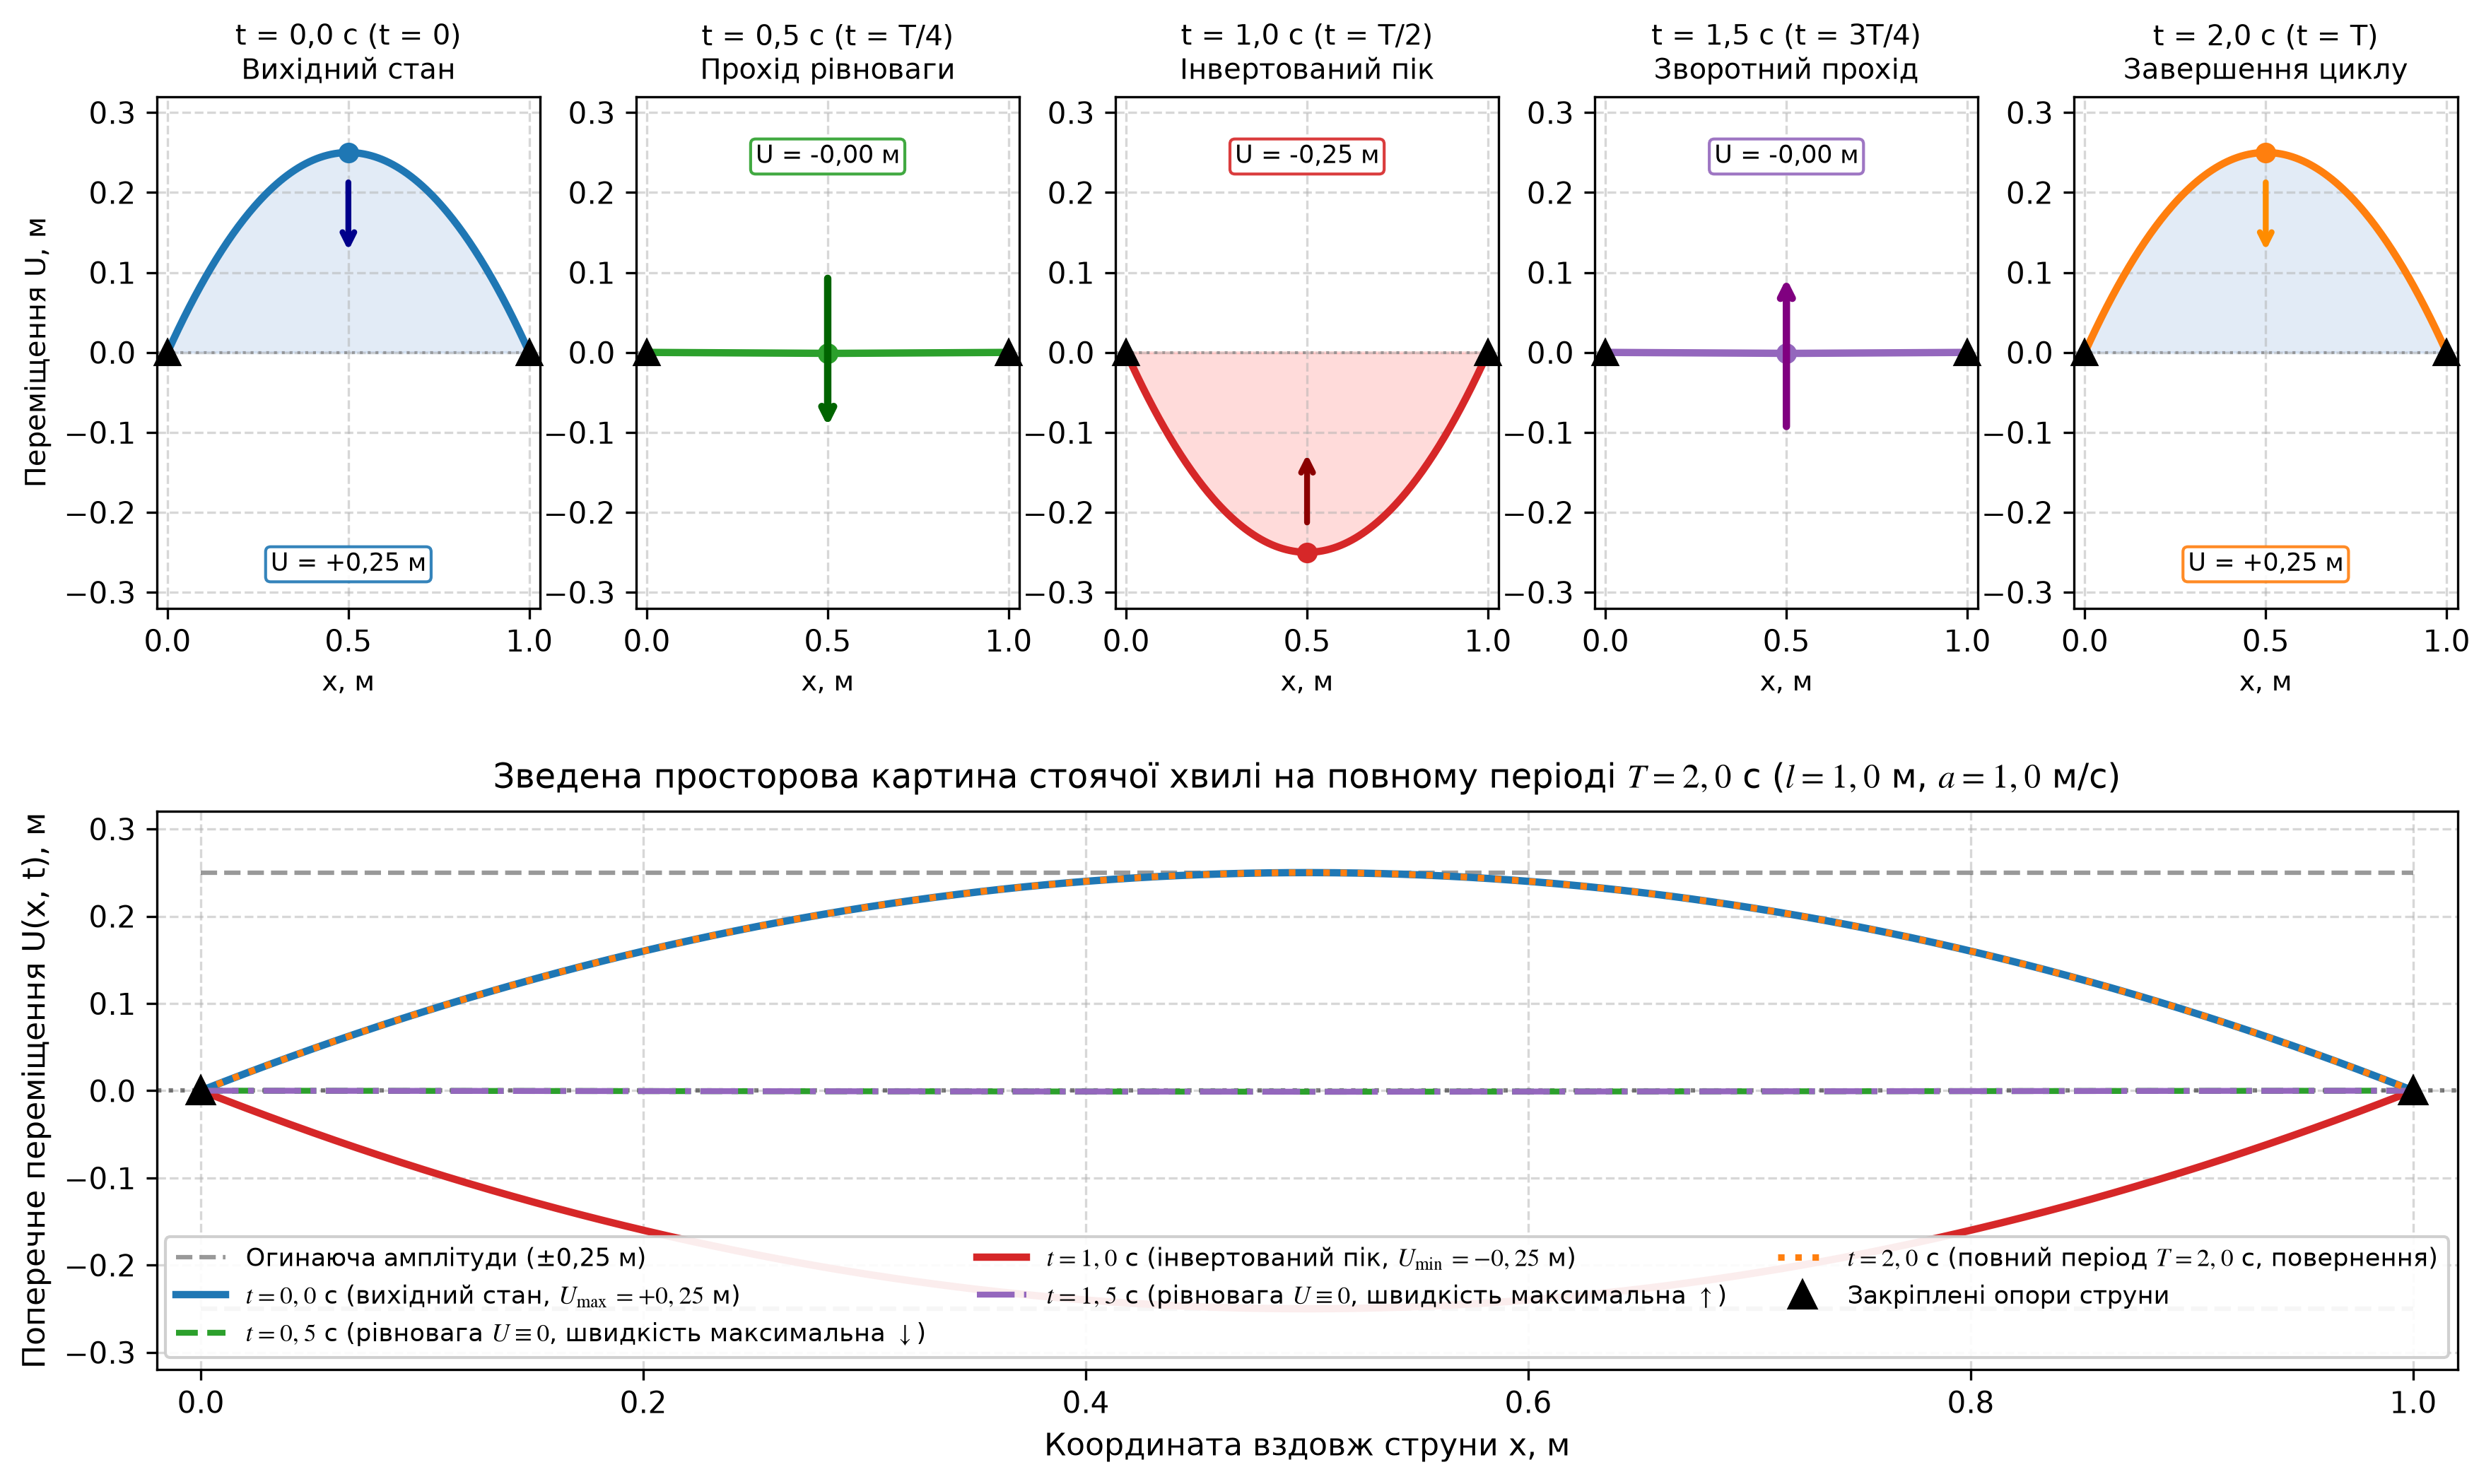

In [4]:
# Таблиця 2.3: Прямий розрахунок просторово-часової матриці прогинів U(x_i, t_j) за рядом Фур'є (K = 41)
x_nodes_23 = np.linspace(0.0, l, 9)
t_nodes_23 = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2, 1.5, 1.8, 2.0]
table_2_3_rows = []
for xv in x_nodes_23:
    row_cells = [f"{xv:.3f}".replace(".", ",")]
    for tv in t_nodes_23:
        val = U_func(xv, tv, K_actual, a, l, A)
        if abs(val) < 5e-5:
            row_cells.append("0,0000")
        else:
            row_cells.append(f"{val:.4f}".replace(".", ",").replace("-", "−"))
    table_2_3_rows.append(row_cells)

print("=" * 118)
print(" ТАБЛИЦЯ 2.3 – Просторово-часова матриця прогинів струни U(x_i, t_j), м, на одному періоді коливань (l=1,0 м, a=1,0 м/с, A=1,0 м^-1, K=41) ")
print("=" * 118)
print(f"{'x, м \\ t, с':^10} | " + " | ".join([f"{str(t_v).replace('.', ','):^7}" for t_v in t_nodes_23]))
print("-" * 118)
for row in table_2_3_rows:
    print(f"{row[0]:^10} | " + " | ".join([f"{v:^7}" for v in row[1:]]))
print("=" * 118)

# Рисунок 2.3: Миттєві форми профілю коливної струни U(x, t) та зведена діаграма стоячої хвилі
x_arr = np.linspace(0.0, l, Nx)
t_arr = np.linspace(0.0, T_period, Nt)
X_mesh, T_mesh = np.meshgrid(x_arr, t_arr)
U_fourier = U_func_grid(X_mesh, T_mesh, K_actual, a, l, A)

fig2_3 = plt.figure(figsize=(14, 7.8), dpi=150)
gs = fig2_3.add_gridspec(2, 5, height_ratios=[1.1, 1.2], hspace=0.38, wspace=0.25)

times_23 = [0.0, 0.5, 1.0, 1.5, 2.0]
phase_labels = [
    "t = 0,0 с (t = 0)\nВихідний стан",
    "t = 0,5 с (t = T/4)\nПрохід рівноваги",
    "t = 1,0 с (t = T/2)\nІнвертований пік",
    "t = 1,5 с (t = 3T/4)\nЗворотний прохід",
    "t = 2,0 с (t = T)\nЗавершення циклу",
]
colors_23 = ["#1f77b4", "#2ca02c", "#d62728", "#9467bd", "#ff7f0e"]

for idx, (t_val, plabel, col) in enumerate(zip(times_23, phase_labels, colors_23)):
    ax = fig2_3.add_subplot(gs[0, idx])
    t_idx = np.argmin(np.abs(t_arr - t_val))
    u_prof = U_fourier[t_idx, :]
    u_center = u_prof[len(x_arr) // 2]

    ax.axhline(0, color="gray", linestyle=":", alpha=0.7, linewidth=1)
    if abs(u_center) > 1e-4:
        fill_col = "#aec7e8" if u_center > 0 else "#ff9896"
        ax.fill_between(x_arr, 0, u_prof, color=fill_col, alpha=0.35)

    ax.plot(x_arr, u_prof, color=col, linewidth=2.5)
    ax.plot(0, 0, "^k", markersize=8, clip_on=False)
    ax.plot(l, 0, "^k", markersize=8, clip_on=False)
    ax.plot(0.5, u_center, "o", color=col, markersize=6)
    ax.set_title(plabel, fontsize=9.5, pad=6)
    ax.set_ylim(-0.32, 0.32)
    ax.set_xlim(-0.03, 1.03)
    ax.set_xlabel("x, м", fontsize=9)
    if idx == 0:
        ax.set_ylabel("Переміщення U, м", fontsize=9.5)
    ax.grid(True, linestyle="--", alpha=0.5)

ax_bot = fig2_3.add_subplot(gs[1, :])
ax_bot.axhline(0, color="black", linestyle=":", alpha=0.5)
ax_bot.plot(x_arr, np.full_like(x_arr, 0.25), "k--", alpha=0.4, label="Огинаюча амплітуди (±0,25 м)")
ax_bot.plot(x_arr, np.full_like(x_arr, -0.25), "k--", alpha=0.4)

comp_labels = [
    r"$t = 0,0$ с (вихідний стан, $U_{\max} = +0,25$ м)",
    r"$t = 0,5$ с (рівновага $U \equiv 0$, швидкість максимальна $\downarrow$)",
    r"$t = 1,0$ с (інвертований пік, $U_{\min} = -0,25$ м)",
    r"$t = 1,5$ с (рівновага $U \equiv 0$, швидкість максимальна $\uparrow$)",
    r"$t = 2,0$ с (повний період $T = 2,0$ с, повернення)",
]
line_styles = ["-", "--", "-", "-.", ":"]
line_widths = [2.5, 2.0, 2.5, 2.0, 2.2]

for t_val, clabel, col, ls, lw in zip(times_23, comp_labels, colors_23, line_styles, line_widths):
    idx_t = np.argmin(np.abs(t_arr - t_val))
    ax_bot.plot(x_arr, U_fourier[idx_t, :], color=col, linestyle=ls, linewidth=lw, label=clabel)

ax_bot.plot(0, 0, "^k", markersize=9, label="Закріплені опори струни")
ax_bot.plot(l, 0, "^k", markersize=9)
ax_bot.set_title(r"Зведена просторова картина стоячої хвилі на повному періоді $T = 2,0$ с ($l = 1,0$ м, $a = 1,0$ м/с)", fontsize=11.5, pad=8)
ax_bot.set_xlabel("Координата вздовж струни x, м", fontsize=10.5)
ax_bot.set_ylabel("Поперечне переміщення U(x, t), м", fontsize=10.5)
ax_bot.set_xlim(-0.02, 1.02)
ax_bot.set_ylim(-0.32, 0.32)
ax_bot.grid(True, linestyle="--", alpha=0.5)
ax_bot.legend(loc="lower center", ncol=3, fontsize=8.5, framealpha=0.92)
plt.tight_layout()
plt.show()

### 2.4.2. Дослідження впливу фазової швидкості $a$ на спектральні та кінематичні характеристики (**Таблиця 2.4**, **Рисунки 2.4, 2.5, 2.6**)

 ТАБЛИЦЯ 2.4 – Вплив фазової швидкості a на спектральні, часові та кінематичні характеристики коливань струни 
Швидкість a, м/с | Період T=2l/a, с | Частота f1, Гц  | Циклів за Δt=2 с  | Макс. швидкість vmax | U(l/2, 0,1 с), м
----------------------------------------------------------------------------------------------------------------
      0,1        |      20,000      |      0,050      |        0,1        |        0,1000        |     +0,2499     
      1,0        |      2,000       |      0,500      |        1,0        |        1,0000        |     +0,2400     
      2,0        |      1,000       |      1,000      |        2,0        |        2,0000        |     +0,2100     
      5,0        |      0,400       |      2,500      |        5,0        |        5,0000        |      0,0000     
      10,0       |      0,200       |      5,000      |       10,0        |       10,0000        |     −0,2500     
     100,0       |      0,020       |     50,000      |       100,0       |     

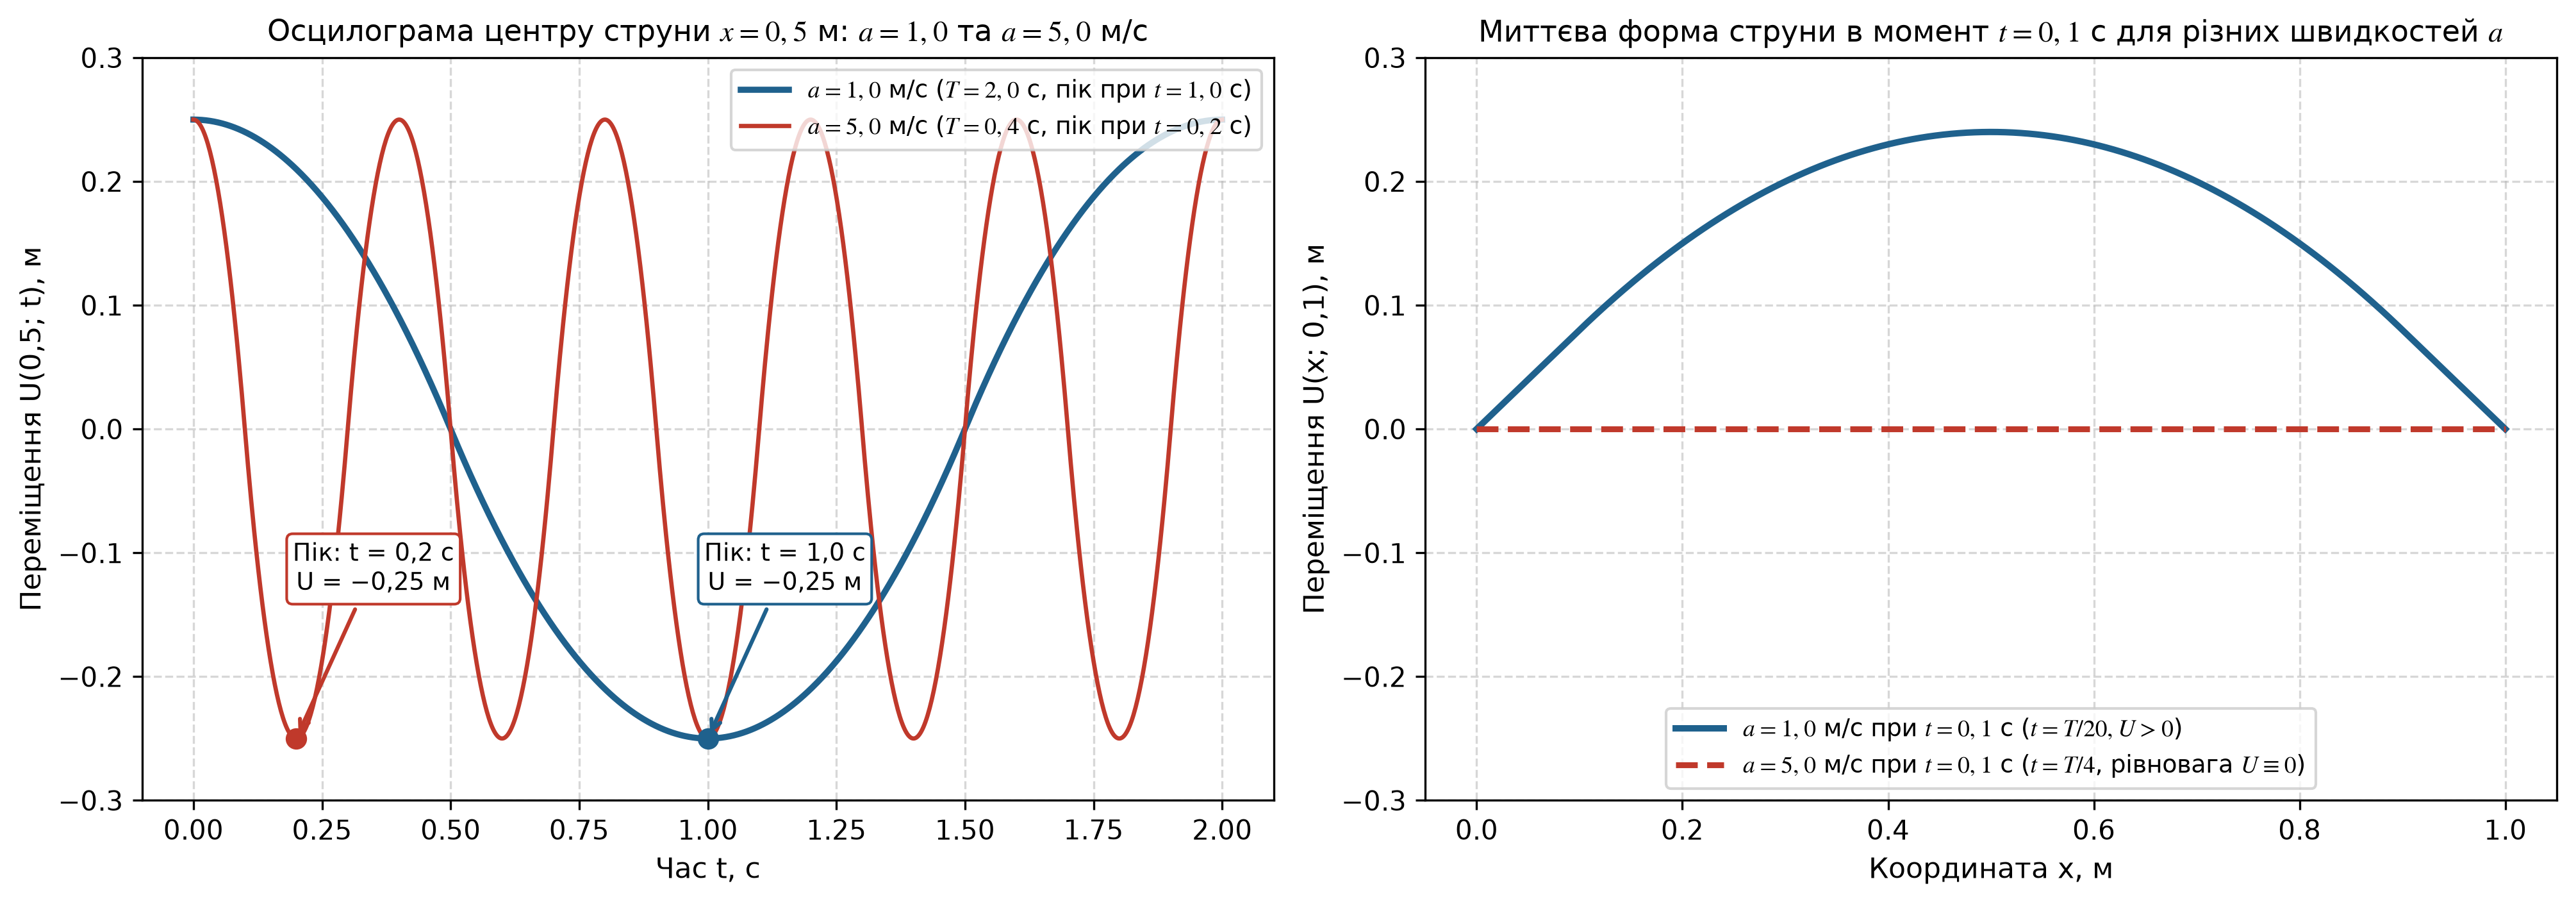

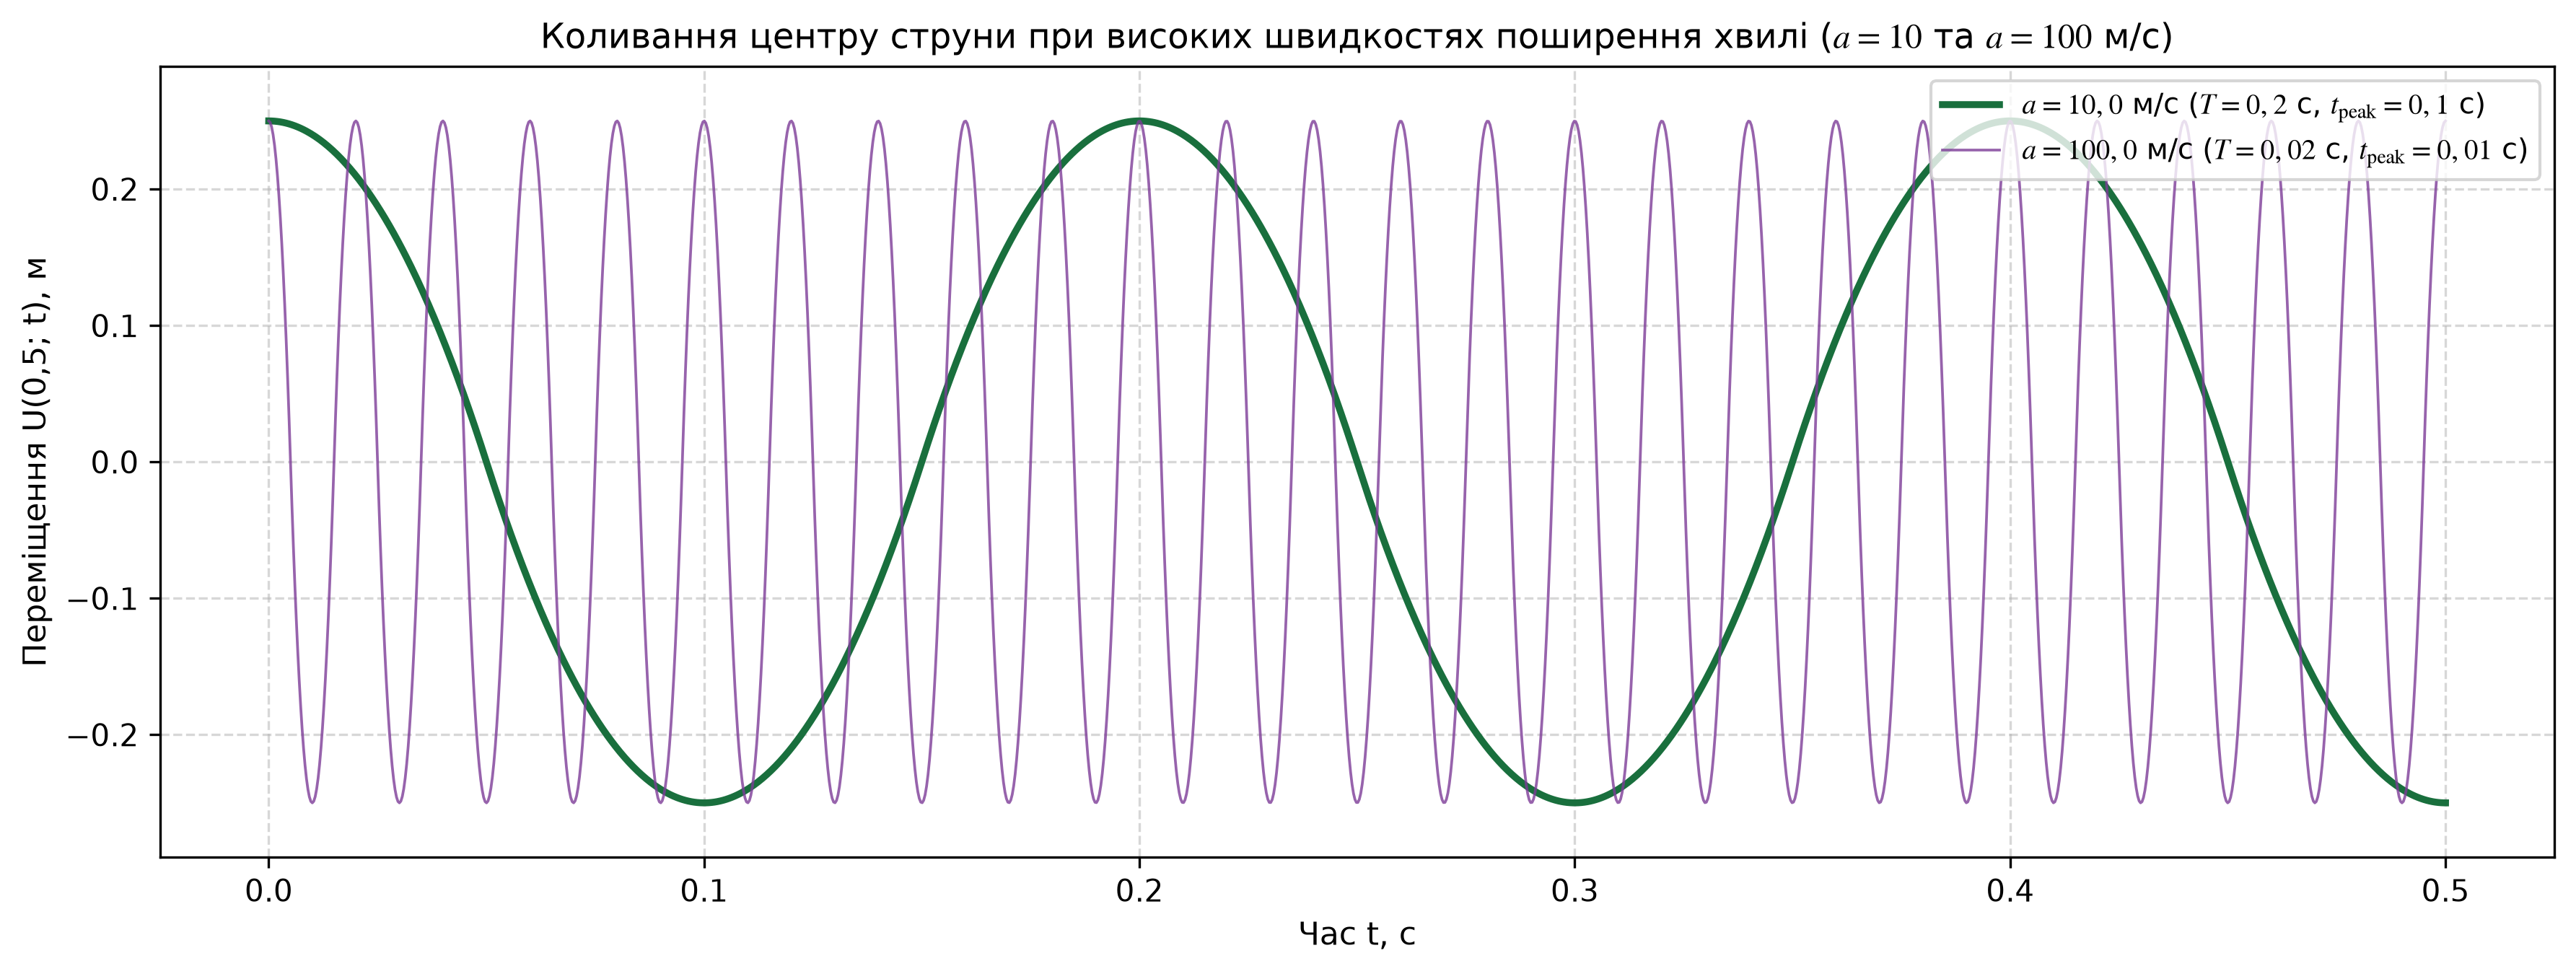

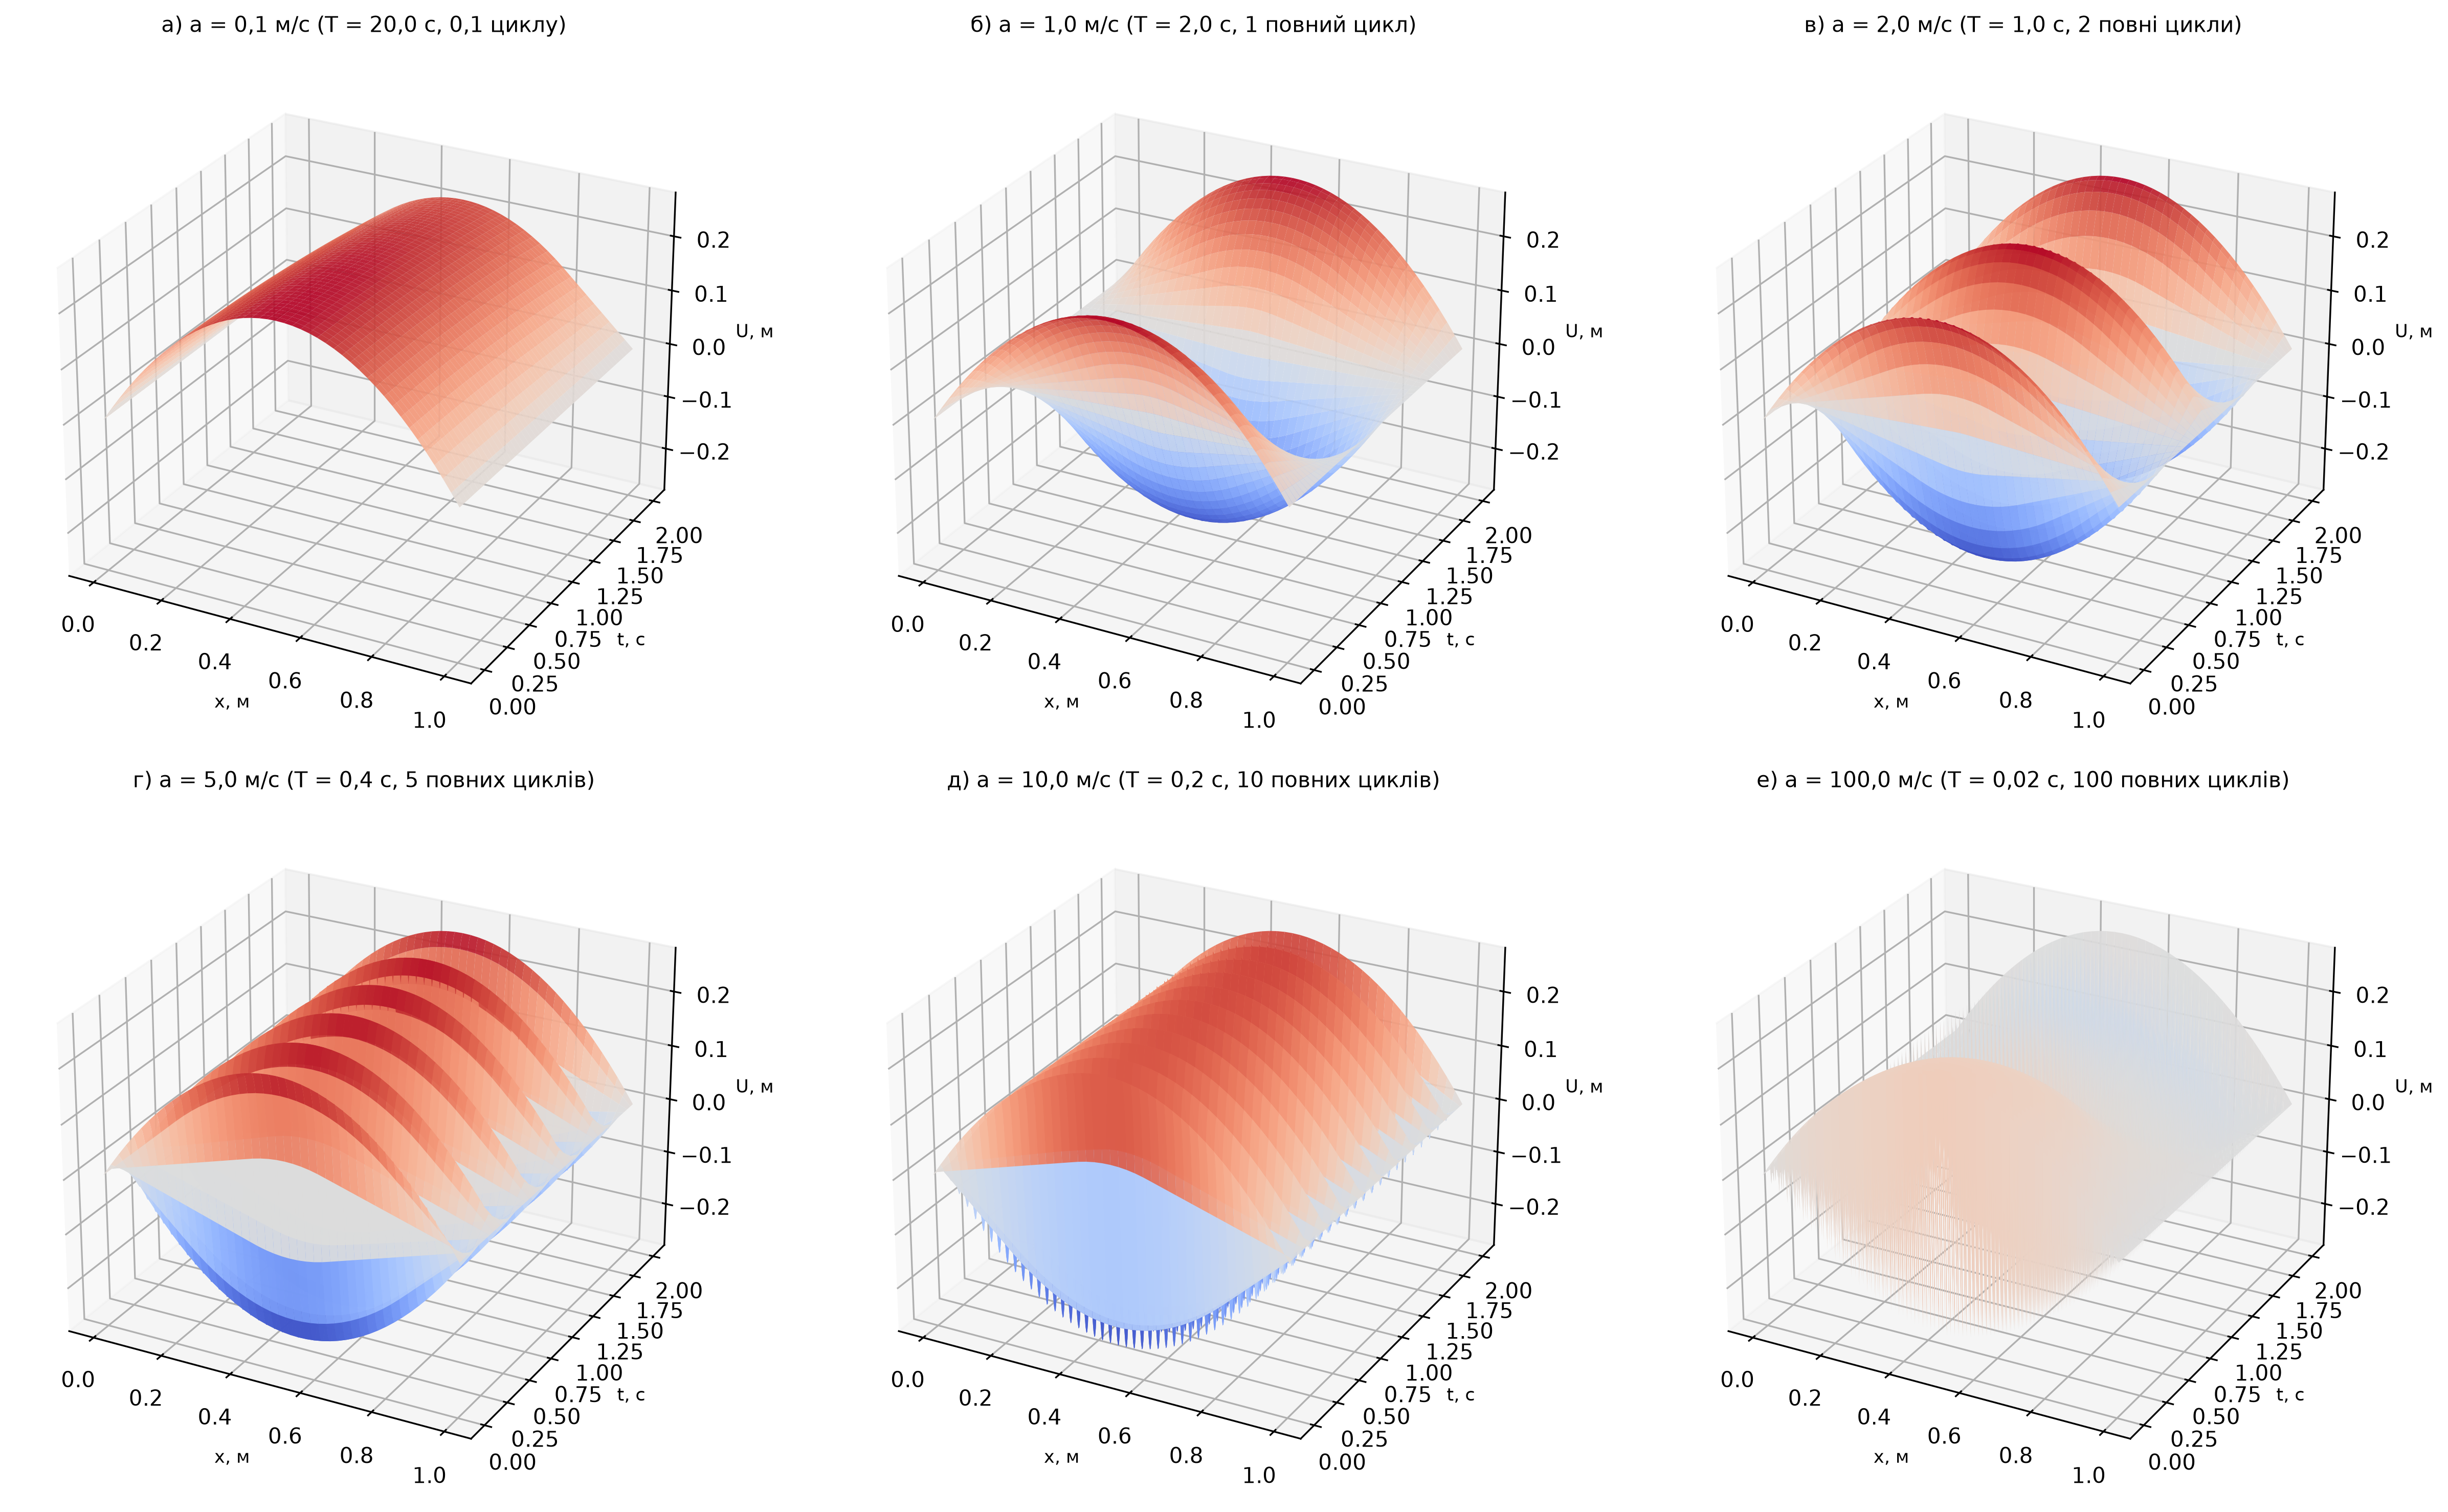

In [5]:
# Таблиця 2.4: Прямий розрахунок впливу фазової швидкості a на спектральні, часові та кінематичні характеристики
a_values = [0.1, 1.0, 2.0, 5.0, 10.0, 100.0]
table_2_4_rows = []
for a_v in a_values:
    T_v = 2.0 * l / a_v
    f1_v = 1.0 / T_v
    cycles_2s = 2.0 / T_v
    vmax_v = a_v * A * l
    u_t01 = U_func(0.5 * l, 0.1, K_actual, a_v, l, A)
    u_t01_str = "0,0000" if abs(u_t01) < 5e-5 else f"{u_t01:+.4f}".replace(".", ",").replace("-", "−")
    table_2_4_rows.append([
        f"{a_v:.1f}".replace(".", ","),
        f"{T_v:.3f}".replace(".", ","),
        f"{f1_v:.3f}".replace(".", ","),
        f"{cycles_2s:.1f}".replace(".", ","),
        f"{vmax_v:.4f}".replace(".", ","),
        u_t01_str,
    ])

print("=" * 112)
print(" ТАБЛИЦЯ 2.4 – Вплив фазової швидкості a на спектральні, часові та кінематичні характеристики коливань струни ")
print("=" * 112)
print(f"{'Швидкість a, м/с':^16} | {'Період T=2l/a, с':^16} | {'Частота f1, Гц':^15} | {'Циклів за Δt=2 с':^17} | {'Макс. швидкість vmax':^20} | {'U(l/2, 0,1 с), м':^16}")
print("-" * 112)
for row in table_2_4_rows:
    print(f"{row[0]:^16} | {row[1]:^16} | {row[2]:^15} | {row[3]:^17} | {row[4]:^20} | {row[5]:^16}")
print("=" * 112)

# Рисунок 2.4: Зіставлення коливань при a = 1,0 м/с та a = 5,0 м/с (а) та миттєві профілі в t = 0,1 с (б)
t_span = np.linspace(0.0, 2.0, 1000)
oscillations = {}
for a_val in a_values:
    u_c = np.zeros_like(t_span)
    for k in range(K_actual):
        m = 2 * k + 1
        u_c += (8.0 * A * (l ** 2) / ((np.pi ** 3) * (m ** 3))) * ((-1) ** k) * np.cos(m * np.pi * a_val * t_span / l)
    oscillations[a_val] = u_c

fig2_4, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=150)
ax1.plot(t_span, oscillations[1.0], color="#1f618d", lw=2.3, label=r"$a = 1,0$ м/с ($T = 2,0$ с, пік при $t = 1,0$ с)")
ax1.plot(t_span, oscillations[5.0], color="#c0392b", lw=1.6, label=r"$a = 5,0$ м/с ($T = 0,4$ с, пік при $t = 0,2$ с)")
ax1.plot(0.2, -0.25, "o", color="#c0392b", ms=7)
ax1.plot(1.0, -0.25, "o", color="#1f618d", ms=7)
ax1.set_title(r"Осцилограма центру струни $x = 0,5$ м: $a = 1,0$ та $a = 5,0$ м/с", fontsize=11)
ax1.set_xlabel("Час t, с", fontsize=10.5)
ax1.set_ylabel("Переміщення U(0,5; t), м", fontsize=10.5)
ax1.set_ylim(-0.30, 0.30)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right", fontsize=9)

u_t01_a1 = np.array([U_func(xv, 0.1, K_actual, 1.0, l, A) for xv in x_plot])
u_t01_a5 = np.array([U_func(xv, 0.1, K_actual, 5.0, l, A) for xv in x_plot])
ax2.plot(x_plot, u_t01_a1, color="#1f618d", lw=2.4, label=r"$a = 1,0$ м/с при $t = 0,1$ с ($t = T/20, U > 0$)")
ax2.plot(x_plot, u_t01_a5, "--", color="#c0392b", lw=2.2, label=r"$a = 5,0$ м/с при $t = 0,1$ с ($t = T/4$, рівновага $U \equiv 0$)")
ax2.set_title(r"Миттєва форма струни в момент $t = 0,1$ с для різних швидкостей $a$", fontsize=11)
ax2.set_xlabel("Координата x, м", fontsize=10.5)
ax2.set_ylabel("Переміщення U(x; 0,1), м", fontsize=10.5)
ax2.set_ylim(-0.30, 0.30)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="lower center", fontsize=9)
plt.tight_layout()
plt.show()

# Рисунок 2.5: Високочастотні коливання на інтервалі t in [0; 0,5] с при a = 10 та a = 100 м/с
t_short = np.linspace(0.0, 0.5, 1500)
u_10 = np.zeros_like(t_short)
u_100 = np.zeros_like(t_short)
for k in range(K_actual):
    m = 2 * k + 1
    c_m = (8.0 * A * (l ** 2) / ((np.pi ** 3) * (m ** 3))) * ((-1) ** k)
    u_10 += c_m * np.cos(m * np.pi * 10.0 * t_short / l)
    u_100 += c_m * np.cos(m * np.pi * 100.0 * t_short / l)

fig2_5, ax = plt.subplots(figsize=(12.0, 4.6), dpi=150)
ax.plot(t_short, u_10, color="#196f3d", lw=2.3, label=r"$a = 10,0$ м/с ($T = 0,2$ с, $t_{\mathrm{peak}} = 0,1$ с)")
ax.plot(t_short, u_100, color="#7d3c98", lw=0.9, alpha=0.8, label=r"$a = 100,0$ м/с ($T = 0,02$ с, $t_{\mathrm{peak}} = 0,01$ с)")
ax.set_title(r"Коливання центру струни при високих швидкостях поширення хвилі ($a = 10$ та $a = 100$ м/с)", fontsize=11.5)
ax.set_xlabel("Час t, с", fontsize=10.5)
ax.set_ylabel("Переміщення U(0,5; t), м", fontsize=10.5)
ax.set_ylim(-0.29, 0.29)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right", fontsize=9.5, frameon=True)
plt.tight_layout()
plt.show()

# Рисунок 2.6: Тривимірні просторово-часові поверхні хвильового поля U(x, t)
fig2_6 = plt.figure(figsize=(16.5, 10.0), dpi=150)
x_3d = np.linspace(0.0, l, 45)
t_3d = np.linspace(0.0, 2.0, 250)
X_3d, T_3d = np.meshgrid(x_3d, t_3d)
letters = ["а", "б", "в", "г", "д", "е"]
cycle_labels = ["0,1 циклу", "1 повний цикл", "2 повні цикли", "5 повних циклів", "10 повних циклів", "100 повних циклів"]

for idx, (a_v, let, c_lbl) in enumerate(zip(a_values, letters, cycle_labels), 1):
    ax3d = fig2_6.add_subplot(2, 3, idx, projection="3d")
    T_per = 2.0 * l / a_v
    U_sub = U_func_grid(X_3d, T_3d, 25, a_v, l, A)
    ax3d.plot_surface(X_3d, T_3d, U_sub, cmap="coolwarm", edgecolor="none", alpha=0.92, vmin=-0.25, vmax=0.25)
    t_per_str = f"{T_per:.1f}" if T_per >= 0.1 else f"{T_per:.2f}"
    ax3d.set_title(f"{let}) a = {str(a_v).replace('.', ',')} м/с (T = {t_per_str.replace('.', ',')} с, {c_lbl})", fontsize=10, pad=6)
    ax3d.set_xlabel("x, м", fontsize=8.5)
    ax3d.set_ylabel("t, с", fontsize=8.5)
    ax3d.set_zlabel("U, м", fontsize=8.5)
    ax3d.set_zlim(-0.28, 0.28)
    ax3d.view_init(elev=26, azim=-62)
plt.tight_layout()
plt.show()

### 2.4.3. Спільний вплив довжини струни $l$, параметра кривини $A$ та швидкості $a$ (**Рисунки 2.7, 2.8, 2.9**, **Таблиці 2.5–2.8**)

 ТАБЛИЦЯ 2.5 – Матриця значень максимального початкового прогину струни h(A, l) = A*l^2/4, м 
 Кривина A \ Довжина l   |  l = 0,5   |  l = 1,0   |  l = 1,5   |  l = 2,0  
--------------------------------------------------------------------------------
        A = 0,5          |  0,03125   |  0,12500   |  0,28125   |  0,50000  
        A = 1,0          |  0,06250   |  0,25000   |  0,56250   |  1,00000  
        A = 1,5          |  0,09375   |  0,37500   |  0,84375   |  1,50000  
        A = 2,0          |  0,12500   |  0,50000   |  1,12500   |  2,00000  

 ТАБЛИЦЯ 2.6 – Матриця значень основного періоду коливань струни T(a, l) = 2l/a, с 
Швидкість a \ Довжина l  |  l = 0,5   |  l = 1,0   |  l = 1,5   |  l = 2,0  
--------------------------------------------------------------------------------
        a = 0,1          |   10,000   |   20,000   |   30,000   |   40,000  
        a = 1,0          |   1,000    |   2,000    |   3,000    |   4,000   
        a = 2,0          |   0,500    |   1

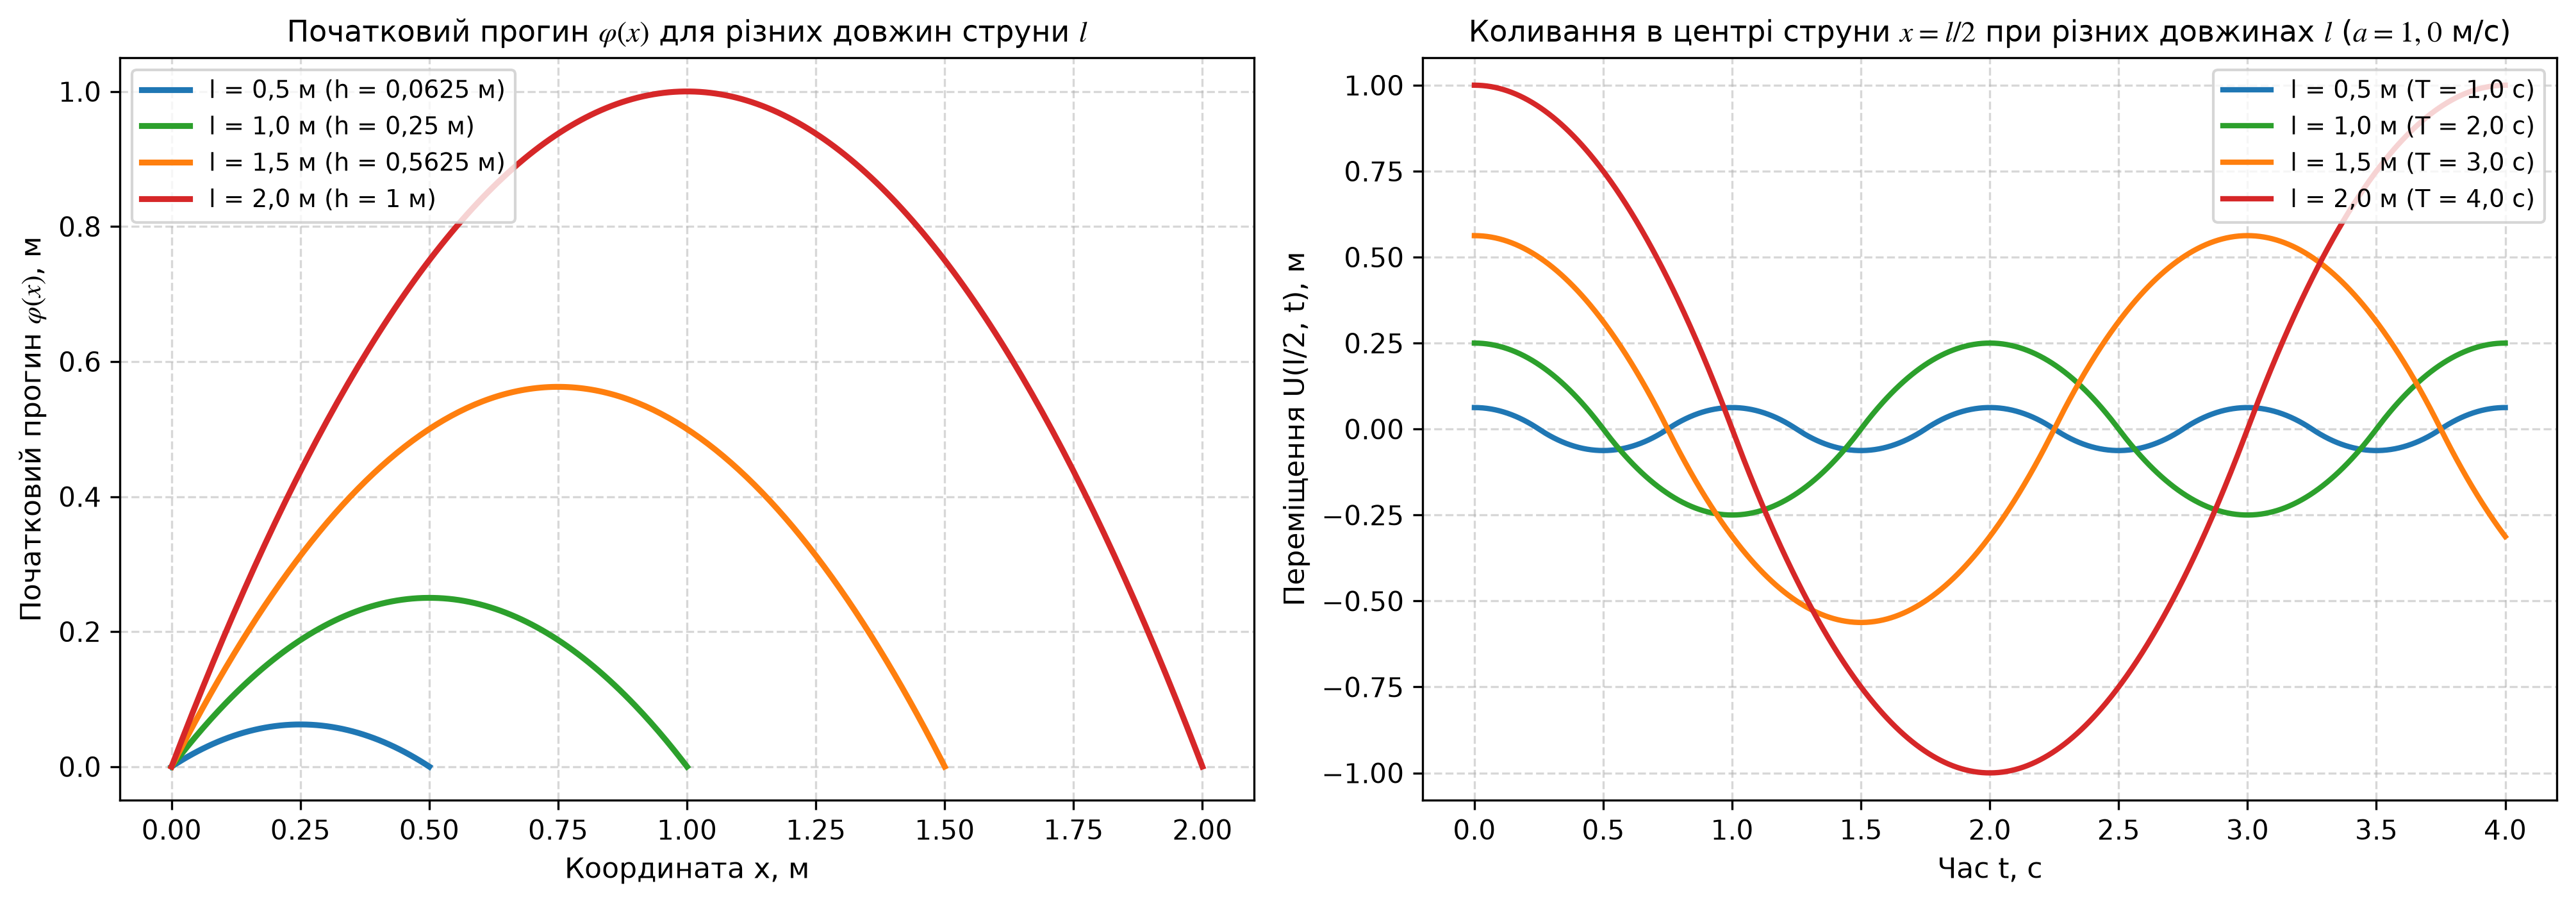

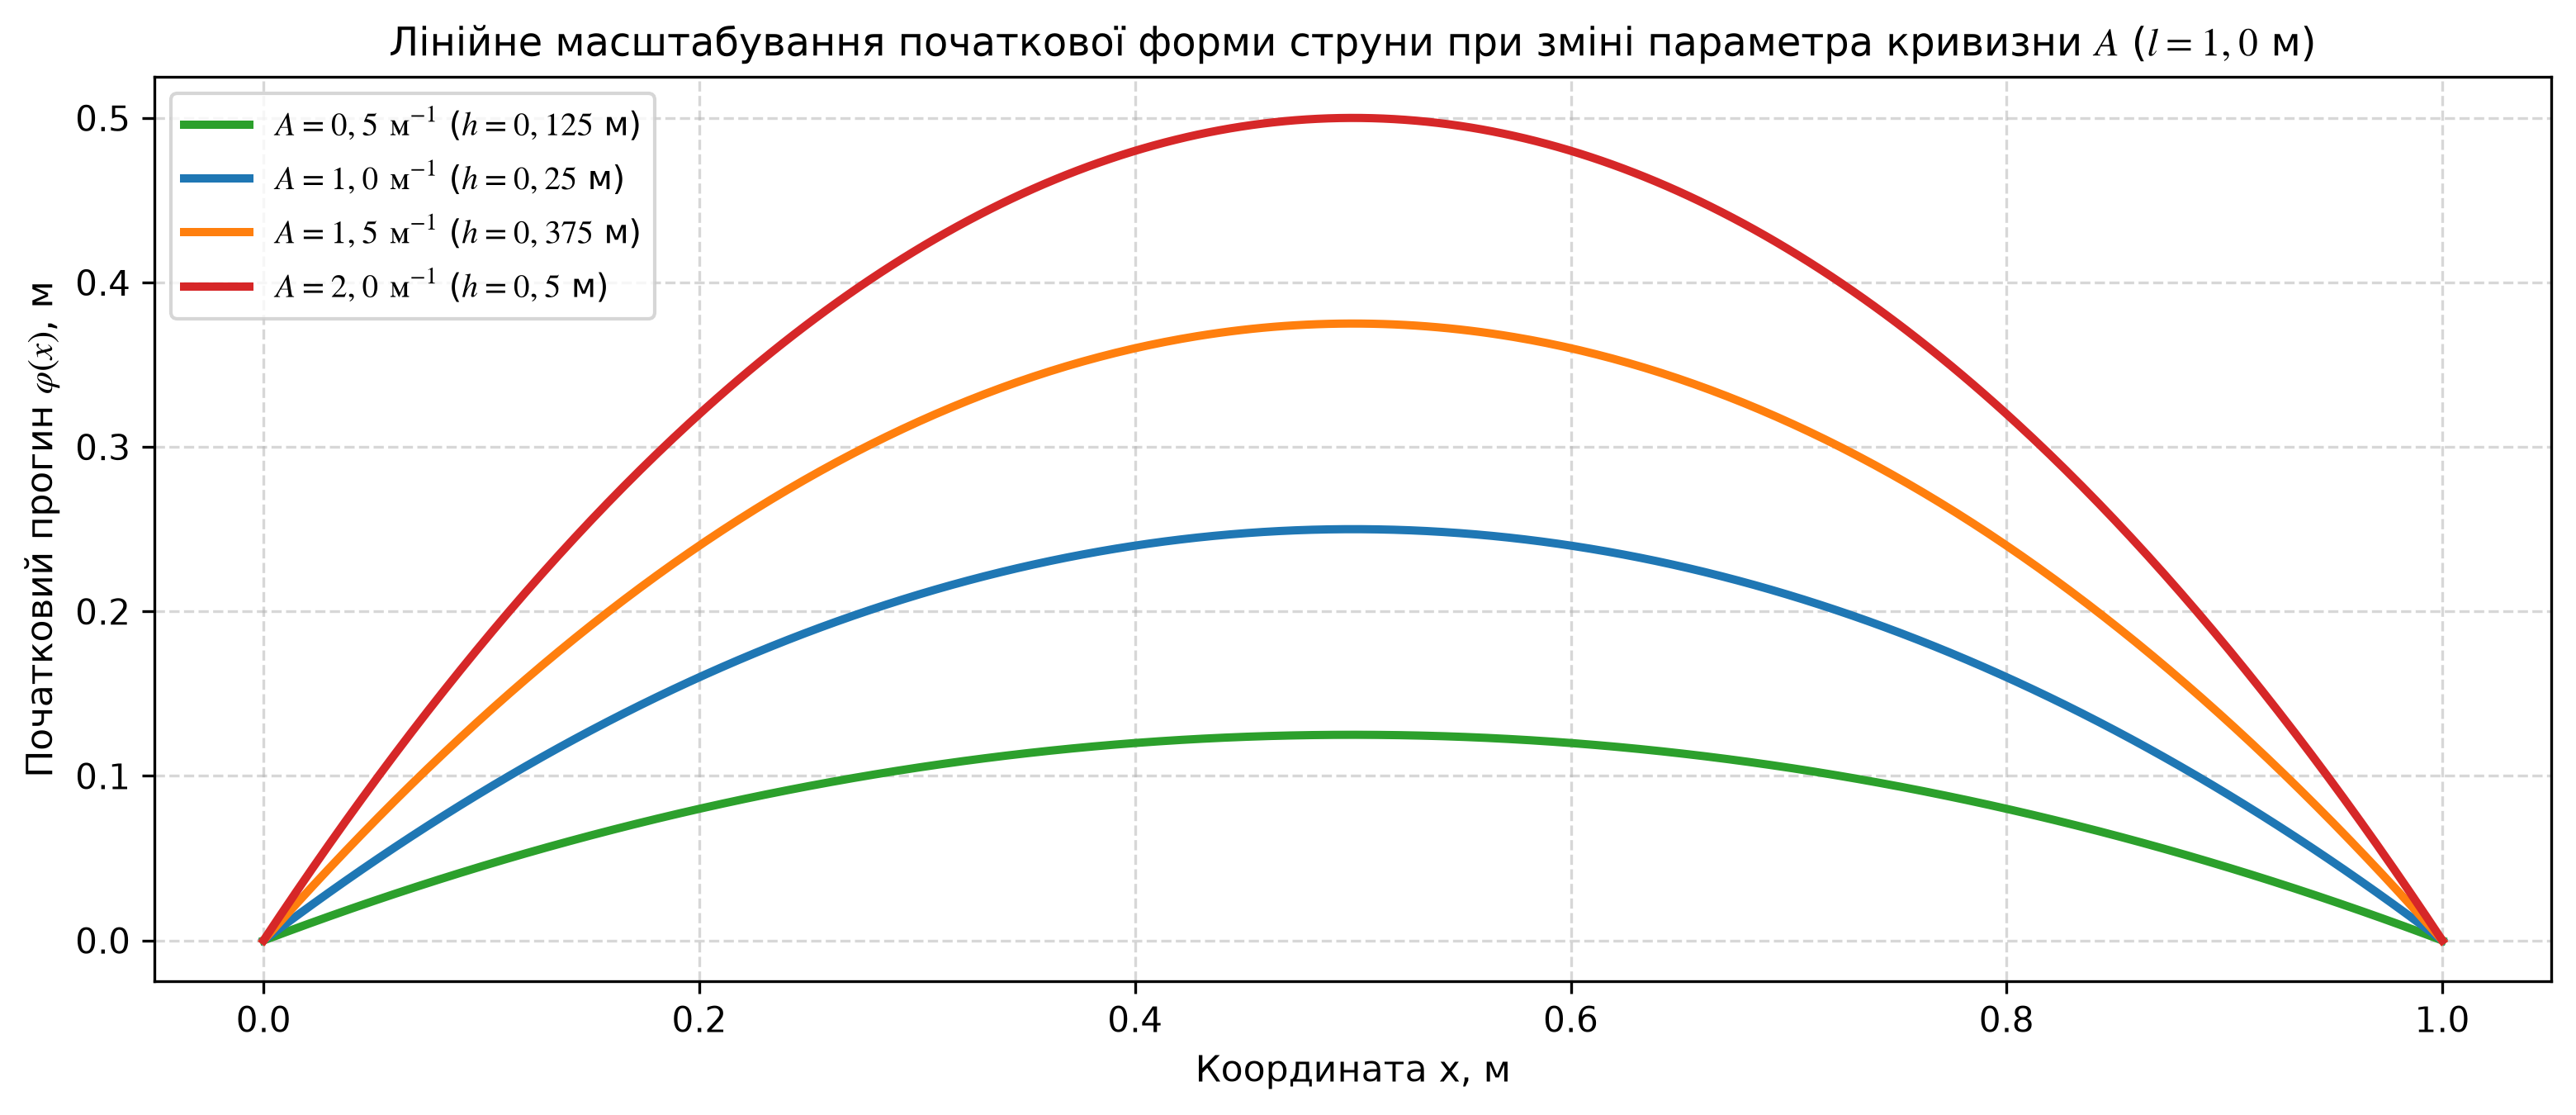

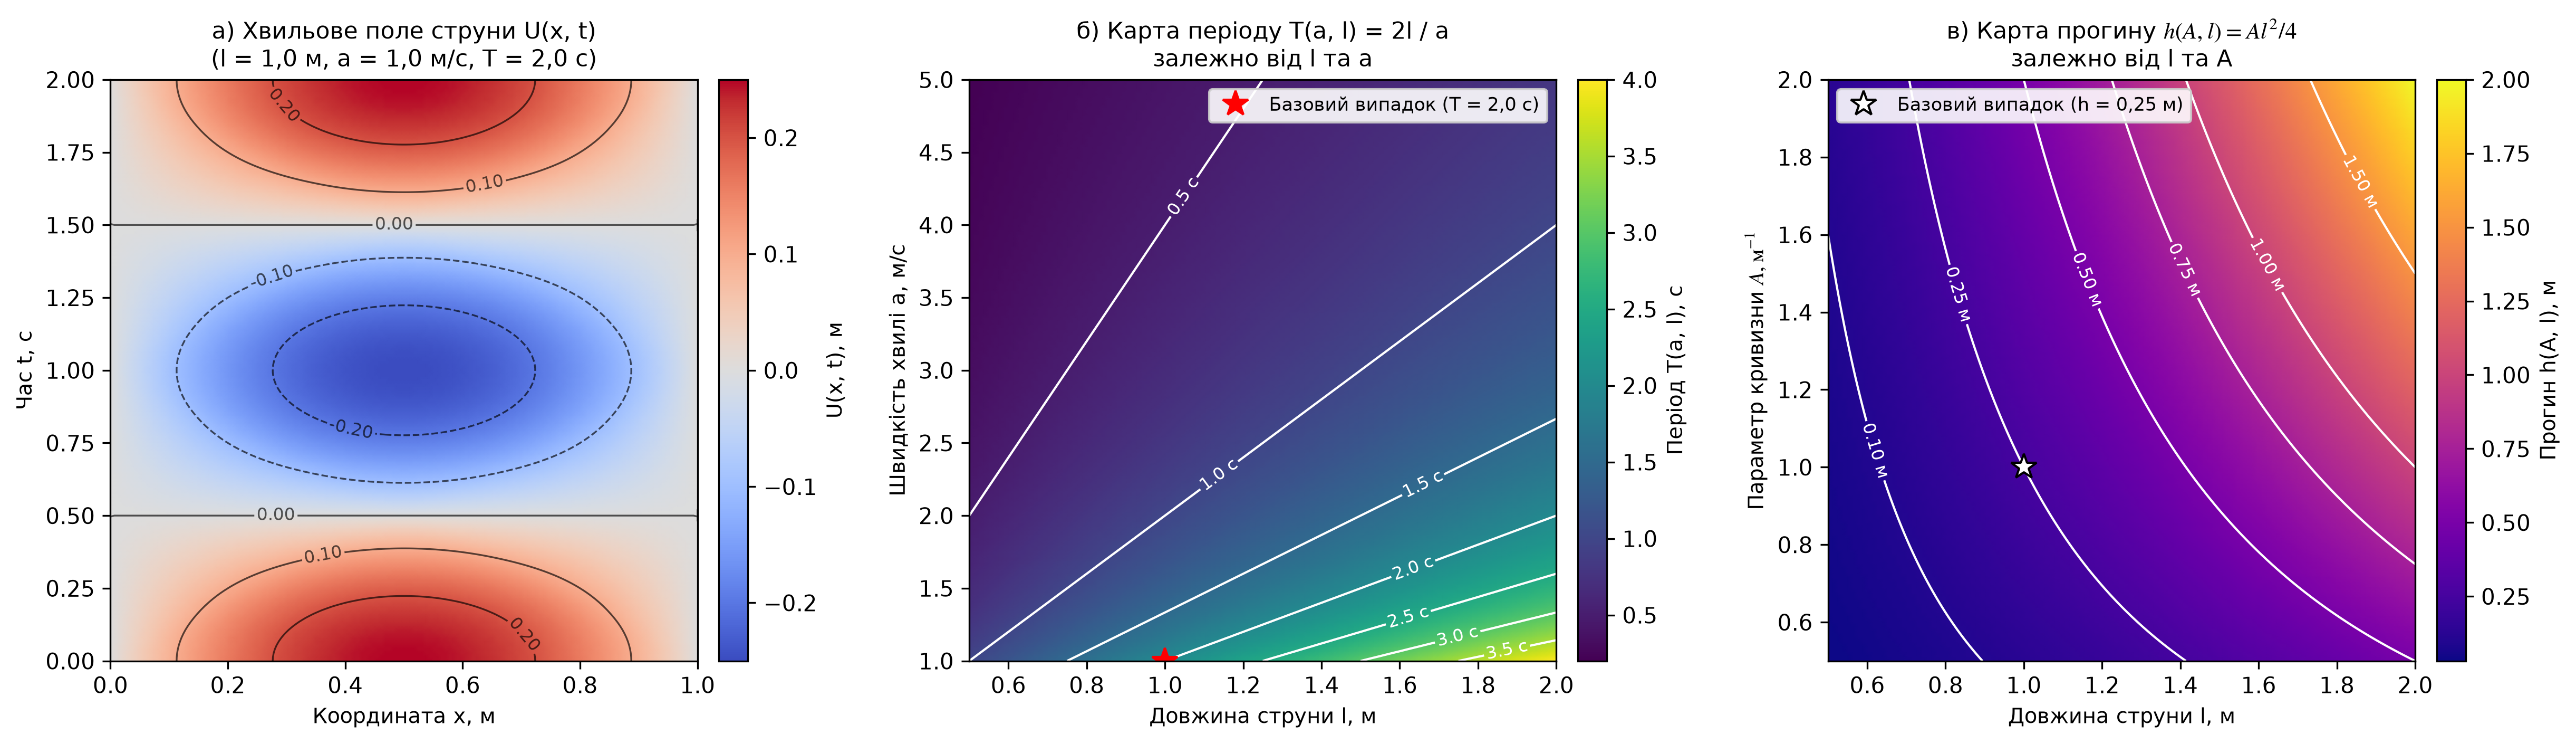

In [6]:
l_values = [0.5, 1.0, 1.5, 2.0]
A_values = [0.5, 1.0, 1.5, 2.0]
cols_l = ["#1f77b4", "#2ca02c", "#ff7f0e", "#d62728"]
t_long = np.linspace(0.0, 4.0, 1000)

# Рисунок 2.7: Вплив довжини струни l in {0,5; 1,0; 1,5; 2,0} м
fig2_7, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=150)
for l_v, col in zip(l_values, cols_l):
    x_s = np.linspace(0.0, l_v, 200)
    phi_s = A * x_s * (l_v - x_s)
    h_s = A * (l_v ** 2) / 4.0
    ax1.plot(x_s, phi_s, color=col, lw=2.2, label=f"l = {str(l_v).replace('.', ',')} м (h = {f'{h_s:.4g}'.replace('.', ',')} м)")
    u_c_l = np.zeros_like(t_long)
    for k in range(K_actual):
        m = 2 * k + 1
        u_c_l += (8.0 * A * (l_v ** 2) / ((np.pi ** 3) * (m ** 3))) * ((-1) ** k) * np.cos(m * np.pi * a * t_long / l_v)
    ax2.plot(t_long, u_c_l, color=col, lw=2.0, label=f"l = {str(l_v).replace('.', ',')} м (T = {2.0*l_v/a:.1f} с)".replace(".", ","))

ax1.set_title(r"Початковий прогин $\varphi(x)$ для різних довжин струни $l$", fontsize=11)
ax1.set_xlabel("Координата x, м", fontsize=10.5)
ax1.set_ylabel(r"Початковий прогин $\varphi(x)$, м", fontsize=10.5)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper left", fontsize=9)

ax2.set_title(r"Коливання в центрі струни $x = l/2$ при різних довжинах $l$ ($a = 1,0$ м/с)", fontsize=11)
ax2.set_xlabel("Час t, с", fontsize=10.5)
ax2.set_ylabel("Переміщення U(l/2, t), м", fontsize=10.5)
ax2.set_ylim(-1.08, 1.08)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

# Рисунок 2.8: Лінійне масштабування профілю при зміні параметра кривини A
cols_A = ["#2ca02c", "#1f77b4", "#ff7f0e", "#d62728"]
fig2_8, ax = plt.subplots(figsize=(10.5, 4.6), dpi=150)
for A_v, col in zip(A_values, cols_A):
    phi_A = A_v * x_plot * (l - x_plot)
    h_A = A_v * (l ** 2) / 4.0
    ax.plot(x_plot, phi_A, color=col, lw=2.4, label=rf"$A = {f'{A_v:.1f}'.replace('.', ',')}\ \mathrm{{м}}^{{-1}}$ ($h = {f'{h_A:.3g}'.replace('.', ',')}$ м)")
ax.set_title(r"Лінійне масштабування початкової форми струни при зміні параметра кривизни $A$ ($l = 1,0$ м)", fontsize=11.5)
ax.set_xlabel("Координата x, м", fontsize=10.5)
ax.set_ylabel(r"Початковий прогин $\varphi(x)$, м", fontsize=10.5)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper left", fontsize=9.5, frameon=True)
plt.tight_layout()
plt.show()

# Рисунок 2.9: Двовимірні теплові карти з ізолініями
x_hm = np.linspace(0.0, l, 150)
t_hm = np.linspace(0.0, T_period, 150)
X_hm, T_hm = np.meshgrid(x_hm, t_hm)
U_hm = U_func_grid(X_hm, T_hm, K_actual, a, l, A)

l_grid_hm = np.linspace(0.5, 2.0, 120)
a_grid_hm = np.linspace(1.0, 5.0, 120)
L_T, A_T = np.meshgrid(l_grid_hm, a_grid_hm)
T_field = 2.0 * L_T / A_T

A_grid_hm = np.linspace(0.5, 2.0, 120)
L_H, A_H = np.meshgrid(l_grid_hm, A_grid_hm)
H_field = A_H * (L_H ** 2) / 4.0

fig2_9, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16.5, 4.8), dpi=150)
im1 = ax1.pcolormesh(X_hm, T_hm, U_hm, cmap="coolwarm", shading="gouraud", vmin=-0.25, vmax=0.25)
cs1 = ax1.contour(X_hm, T_hm, U_hm, levels=[-0.2, -0.1, 0.0, 0.1, 0.2], colors="black", linewidths=0.8, alpha=0.65)
ax1.clabel(cs1, inline=True, fontsize=8, fmt="%.2f")
plt.colorbar(im1, ax=ax1, pad=0.03).set_label("U(x, t), м", fontsize=9.5)
ax1.set_title("а) Хвильове поле струни U(x, t)\n(l = 1,0 м, a = 1,0 м/с, T = 2,0 с)", fontsize=10.5)
ax1.set_xlabel("Координата x, м", fontsize=9.5)
ax1.set_ylabel("Час t, с", fontsize=9.5)

im2 = ax2.pcolormesh(L_T, A_T, T_field, cmap="viridis", shading="gouraud")
cs2 = ax2.contour(L_T, A_T, T_field, levels=[0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5], colors="white", linewidths=1.0)
ax2.clabel(cs2, inline=True, fontsize=8, fmt="%.1f с")
plt.colorbar(im2, ax=ax2, pad=0.03).set_label("Період T(a, l), с", fontsize=9.5)
ax2.plot(1.0, 1.0, "r*", ms=12, label="Базовий випадок (T = 2,0 с)")
ax2.legend(loc="upper right", fontsize=8.5, framealpha=0.9)
ax2.set_title("б) Карта періоду T(a, l) = 2l / a\nзалежно від l та a", fontsize=10.5)
ax2.set_xlabel("Довжина струни l, м", fontsize=9.5)
ax2.set_ylabel("Швидкість хвилі a, м/с", fontsize=9.5)

im3 = ax3.pcolormesh(L_H, A_H, H_field, cmap="plasma", shading="gouraud")
cs3 = ax3.contour(L_H, A_H, H_field, levels=[0.1, 0.25, 0.5, 0.75, 1.0, 1.5], colors="white", linewidths=1.0)
ax3.clabel(cs3, inline=True, fontsize=8, fmt="%.2f м")
plt.colorbar(im3, ax=ax3, pad=0.03).set_label("Прогин h(A, l), м", fontsize=9.5)
ax3.plot(1.0, 1.0, "w*", ms=12, markeredgecolor="black", label="Базовий випадок (h = 0,25 м)")
ax3.legend(loc="upper left", fontsize=8.5, framealpha=0.9)
ax3.set_title(r"в) Карта прогину $h(A, l) = Al^2/4$" + "\nзалежно від l та A", fontsize=10.5)
ax3.set_xlabel("Довжина струни l, м", fontsize=9.5)
ax3.set_ylabel(r"Параметр кривизни $A, \mathrm{м}^{-1}$", fontsize=9.5)
plt.tight_layout()
plt.show()

# Таблиці 2.5 – 2.8
print("=" * 80)
print(" ТАБЛИЦЯ 2.5 – Матриця значень максимального початкового прогину струни h(A, l) = A*l^2/4, м ")
print("=" * 80)
print(f"{'Кривина A \\ Довжина l':^24} | {'l = 0,5':^10} | {'l = 1,0':^10} | {'l = 1,5':^10} | {'l = 2,0':^10}")
print("-" * 80)
for A_v in A_values:
    r_vals = [f"{A_v * (l_v ** 2) / 4.0:.5f}".replace(".", ",") for l_v in l_values]
    print(f"{f'A = {str(A_v).replace(".", ",")}':^24} | " + " | ".join([f"{v:^10}" for v in r_vals]))
print("=" * 80)

print("\n" + "=" * 80)
print(" ТАБЛИЦЯ 2.6 – Матриця значень основного періоду коливань струни T(a, l) = 2l/a, с ")
print("=" * 80)
print(f"{'Швидкість a \\ Довжина l':^24} | {'l = 0,5':^10} | {'l = 1,0':^10} | {'l = 1,5':^10} | {'l = 2,0':^10}")
print("-" * 80)
for a_v in a_values:
    r_vals = [f"{2.0 * l_v / a_v:.3f}".replace(".", ",") for l_v in l_values]
    print(f"{f'a = {str(a_v).replace(".", ",")}':^24} | " + " | ".join([f"{v:^10}" for v in r_vals]))
print("=" * 80)

# Таблиця 2.7: Прямий розрахунок прогину в центрі струни U(l/2, t0 = 0,5 с) за рядом Фур'є (K = 41)
table_2_7_rows = []
for a_v in a_values:
    row_cells = [f"a = {str(a_v).replace('.', ',')}"]
    for l_v in l_values:
        val_27 = U_func(0.5 * l_v, 0.5, K_actual, a_v, l_v, 1.0)
        if abs(val_27) < 5e-5:
            row_cells.append("0,0000")
        else:
            row_cells.append(f"{val_27:+.4f}".replace(".", ",").replace("-", "−"))
    table_2_7_rows.append(row_cells)
print("\n" + "=" * 80)
print(" ТАБЛИЦЯ 2.7 – Прогин у центрі струни U(l/2, t0), м, у момент t0 = 0,5 с залежно від a та l (A = 1,0 м^-1) ")
print("=" * 80)
print(f"{'Швидкість a \\ Довжина l':^24} | {'l = 0,5':^10} | {'l = 1,0':^10} | {'l = 1,5':^10} | {'l = 2,0':^10}")
print("-" * 80)
for row in table_2_7_rows:
    print(f"{row[0]:^24} | " + " | ".join([f"{v:^10}" for v in row[1:]]))
print("=" * 80)

a_fine_28 = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
print("\n" + "=" * 86)
print(" ТАБЛИЦЯ 2.8 – Деталізована матриця прогинів центра струни U(l/2, t0), м, у момент t0 = 0,25 с ")
print("=" * 86)
print(f"{'Швидкість a \\ Довжина l':^24} | {'l = 0,5':^12} | {'l = 1,0':^12} | {'l = 1,5':^12} | {'l = 2,0':^12}")
print("-" * 86)
for a_v in a_fine_28:
    row_cells = []
    for l_v in l_values:
        val_exact = U_dalembert_exact(0.5 * l_v, 0.25, a_v, l_v, 1.0)
        s_val = "0,000000" if abs(val_exact) < 1e-12 else f"{val_exact:+.6f}".replace(".", ",").replace("-", "−")
        row_cells.append(s_val)
    print(f"{f'a = {a_v:.1f}'.replace('.', ','):^24} | " + " | ".join([f"{v:^12}" for v in row_cells]))
print("=" * 86)